# E87 · Pricing a model: should a charity buy a flight-level forecast?

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify. Opens the large-model series |
| **Data** | Real: BTS Reporting Carrier On-Time Performance, all 14,080,680 rows of 2024-2025, kept here as 494,547 flight x month cells and one month of rows, with integer codes and no names. Rows 1-3 of the price table use the forest of E86, bike hires and daily industry returns |
| **Time** | About 12-13 minutes on 2 cores (measured, three model fits, in this environment and in a plain install). 8 cores were not timed, and a laptop may differ. No GPU is used: every GPU number is a stored table |
| **You will learn** | How to price a model: rate x gradients + memory + precision · why a rate belongs to a cost shape · timing a PyMC or JAX gradient honestly · reading a claim off an iso-cost map · a ladder of rungs from a counting rule to a hierarchical beta-binomial · redrawing the month when you forecast one · fixing a decision rule before reading any score · writing a price someone can check |

## The brief

> *From the research lead of a passenger-rights charity. The charity and its lead are fictional,
> invented for this notebook; the data and the regulation are real.* US rules treat a flight that
> is more than 30 minutes late or cancelled over half the time in a month as chronically delayed,
> and holding one out for more than four consecutive months as a violation. We want a monthly
> watch list of the 50 flights most likely to be flagged next month. A contractor quotes a
> flight-level model on two years of every US flight: "two hours on one GPU, from a published
> rate". Our analyst says a table of counts will do. I have one workstation for one night a
> month, about 8 hours. **Do I approve the quote, buy something smaller, or refuse? Give me a
> price I can check, and tell me whether the bigger model changes the list.**

## The answer, before the working

**Do not approve the quote as written. Run the table of counts now, and pay for one small test of
the middle model on all carriers before buying anything larger.** This notebook can support that
much, and no more: the row-level model was priced, never fitted, and the middle model was fitted
on one carrier.

- **The two hours is unproven.** It holds only at about 46,000 gradients or fewer, and every
  count we can point to is higher or does not apply. One fit of the row-level model on all 24
  months prices at about 2.6 hours at 60,000 gradients and 7.0 hours at 160,000. Three test
  months cost 5.9-16 hours on all earlier rows, or 3.9-10.5 hours on a 12-month window. This is
  extrapolated from a measured 10-million-row gradient, and the gradient counts are assumptions:
  at 60,000 the quote misses by only 1.3x. E86's own warmup restart is inside the 160,000, and
  any further restart is not.
- **The gap is not where we expected it.** The contractor's 0.15 s a gradient is about right by
  accident: a rate about 5x too slow cancels 5x too few lookups. What is missing is a gradient
  count, and a test needs three fits where the quote prices one. We expected a slow reverse
  lookup, and the fix we planned, sorting the rows, made the GPU slower on one scatter at 10M
  rows, and changed nothing on a month of rows with five lookups.
- **One fit may fit a night, but nobody has shown it.** 7.0 of 8 hours is time alone. The float32
  total at 14 million rows was never tested, and the row-level model has about 30x the parameters
  of the model that gave the 160,000. The recipe behind that count also keeps a d x d table of
  about 2,080 GiB at this size, so it cannot run here as it stands.
- **Does a bigger model change the list?** On one mid-size carrier the middle model, R2, changes
  2-3 of a list of 10 and about half of a list of 50. Our rule buys R2 at two of three test
  months and the counting rule R1 at the third, so R2 on this carrier. It was fixed before any
  score was read, with the limits section 7 lists, and it leans towards the dearer rung. The
  margin is thin: R2's score is clearly better only in the worst month, July 2025, and in both
  other months R1 sat within one standard error. R1 lost October by one flight of list overlap, 7
  shared where the rule asks for 8, and April's pick moves with the seed (section 7). In a list
  of 10 both rungs caught the same number of flagged flights: 0, 4 and 0. In a list of 50 R2
  caught 3, 17 and 2 against 0, 10 and 0, and July's gain has a 5-95% range of about 0 to 14.
  This carrier has far more new flights than the country as a whole, so this is more a test of
  how R2 treats new flights than of flight history.
- **The analyst is partly right.** Nationally, the two counting rules take under a second. Their
  top 50 held 4-36 and 9-35 flagged flights in the three months, with neither winning all three,
  but those counts use each target month's own schedule. Built from last month's file alone, as a
  real list must be, they held 4-35 and 6-31. That is a usable list today, and far better than
  chance. It says nothing about what R2 would add nationally.
- **What the next test costs.** Two versions of R2 price for the same three months, and neither
  is the R2 checked here, which gave every flight of one carrier its own effect. ChEES on a cut
  model, where 24% of cells lose their flight's own effect, prices at about 16-43 minutes on the
  GPU, plus any further warmup restarts. ChEES has never run on R2, and its gradient counts are
  assumptions. nutpie with every flight prices at about 4.8-5.1 hours or more on 2 CPU cores,
  scaled by cells at the one carrier's gradient count. Both are extrapolated. Either fits one
  night at those figures, the GPU version easily and the CPU version only if the count holds,
  since one more tree doubling makes it about 10 hours. Either way the question can be settled
  for far less than a row-level run.

**A warning on reruns.** Timings move between runs, so timing prose gives ranges. Repeat runs
here, on the same seed and 2 cores, gave identical fits, scores and lists, with and without the
GPU extra installed. Do not rely on that elsewhere: nutpie is not promised to be
bit-reproducible, and another core count or library version can move a thin result like the one
above. The stored GPU tables are one set of measurements from one machine, and a reader's run
does not reproduce them.

## What a flag means

14 CFR 399.81(c) defines a chronically delayed flight as a domestic flight operated at least 10
times a month that arrives more than 30 minutes late, cancellations included, more than 50
percent of the time in that month. A carrier's departures in one city-pair market within 30
minutes of the most frequent scheduled time count as one flight. **Flagged** below means a rule
flight that met this test in a month, as we code it. Directions are kept apart, diversions do not
count as late, and months are linked by our own rule. It is an estimate, not DOT's own
computation and not a finding about any carrier. A watch list here says "likely to be flagged",
never "chronically delayed". Carriers, airports, tails and flights carry integer codes, and the
carrier in section 6 is called the mid-size carrier. No name is stored in this repository, but
that is not anonymity: anyone with the public BTS files can match the codes back, by row order in
the month table or by counts. No licence or terms were found for this BTS table, so only re-coded
tables are kept here, one of them row-level for one month.

## Modelling decisions, stated up front

| Decision | What this notebook does | Why, and what it costs |
|---|---|---|
| **Rungs** | R0 persistence, R1 a beta-binomial count per flight, R2 a hierarchical beta-binomial on flight x month cells, R3 Bernoulli on rows | A dearer rung is bought only if the cheaper one scores more than one SE below the best, or its list differs from the next rung's. See the rung rule below |
| **R3** | **Priced only**, at any size | It needs a float32 test and a gradient count that nobody has measured |
| **R2 on all carriers** | **Priced only**. Fitted on one carrier chosen by size alone, which turned out to be unusual (section 6) | On the GPU, a national run breaks a 60-second job limit on this machine, and warmup cannot checkpoint. On 2 CPU cores it prices in hours, far past the 15 minutes allowed for a reader's run. So there is no national R2 answer here |
| **Target** | Flagged next month among flights operated at least 10 times that month. Three months: 2025-04, 2025-07, 2025-10 | The month's operations count as known schedule. A real watch list must guess it, and section 5 prints what that costs. Flags swing 67-fold between months, so results are never pooled |
| **History** | The 12 months before each target, assuming last month's file is in hand | A real monthly cycle may be a file behind. 12 months was fixed, not tested, and section 7 shows a shorter window doing better in July |
| **One carrier's list** | 10 flights, with 8 shared as the overlap test. The brief's 50 is printed but decides nothing | 50 of about 600 flights is far less selective than 50 of 20,000. Length matters: 10 is the only tested length where R1 wins any month (section 7) |
| **Rung rule** | Cheapest rung within one bootstrap SE of the best log score whose list shares at least 8 of 10 with the next rung's. Fixed before any score was read, with the limits in section 7 | If origins disagree, two of three decide. Three months cannot carry a pooled interval. The overlap test measures difference, not benefit, so the rule leans towards the dearer rung |
| **R2's form** | Non-centred flight effects, nutpie, 4 chains, 1,000 tuning and 1,000 draws | The centred form was tried only in a short smoke run, so nothing here compares the two |
| **GPU numbers** | Loaded from `results/E87/`, measured on one RTX 3090 Ti | A reader's run never starts a GPU. CPU figures are on 2 threads, so they cannot show that a GPU beats a well-run CPU |

## The plan

1. The price, before anything else
2. The flights
3. What a gradient costs, and the first failure
4. The quote, and the walls behind it
5. Two counting rules, and the second failure
6. R2 on one carrier, and the third failure
7. Does the bigger model change the list?
8. What this run cost, and what to tell the charity

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain
os.environ["JAX_PLATFORMS"] = "cpu"  # the GPU numbers here are stored: a reader's run never starts one

import contextlib
import gc
import logging
import time
import warnings

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
import xarray as xr
from jax.flatten_util import ravel_pytree
from jax.scipy.special import gammaln as jax_gammaln
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter, NullFormatter
from pymc.sampling.jax import get_jaxified_logp
from scipy import stats
from scipy.special import betaln, expit, gammaln

from pymc_challenges import data
from pymc_challenges.bigrun import PreflightError, Store, banner, estimated, extrapolated, git_hash, measured, time_gradient

RANDOM_SEED = 87
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message=".*Explicitly requested dtype.*")
jax.config.update("jax_enable_x64", False)  # importing PyMC switches x64 on

LEVEL = os.environ.get("PYMC_CHALLENGES_RUN", "").strip().lower() or "small"
if LEVEL != "small":
    raise PreflightError(f"PYMC_CHALLENGES_RUN={LEVEL!r}: E87 has one level, small. The row-level run was "
                         "priced and never made, so there is nothing to replay or scale up.")
assert jax.default_backend() == "cpu", "this notebook never starts a GPU"

CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
CHAINS_AT_ONCE = min(4, CORES)
TUNE, DRAWS = 1000, 1000  # nutpie's default 400 tuning steps is not assumed: see section 6
TARGETS = (15, 18, 21)  # 2025-04, 2025-07, 2025-10 as month numbers, with 2024-01 as 0
TARGET_NAMES = {15: "2025-04", 18: "2025-07", 21: "2025-10"}
WINDOW = 12  # months of history behind each list
LIST_SIZE, NEEDED = 10, 8  # one carrier's list, and the overlap the rung rule asks for
MEASURED, EXTRA, ALARM, CALM, MUTED = "#0b6e8a", "#a85a00", "#b2182b", "#2a7f62", "#8a8a8a"
RUNG_COLOUR = {"R0": "#8a8a8a", "R1": "#0b6e8a", "R2": "#b2182b"}
PRICE = {}


@contextlib.contextmanager
def stage(name):
    """Add the time spent in this block to the price table printed at the end."""
    start = time.perf_counter()
    yield
    PRICE[name] = PRICE.get(name, 0.0) + time.perf_counter() - start


store = Store("E87")
pilot = store.load_json("pilot_2026-11-02")  # the GPU pilot: see plans/large/E87.md section 13
extra_gpu = store.load_json("gpu_rows_2026-11-02")  # rows 2, 3 and a month of rows on the GPU
summary = store.load_json("data_summary")  # counts over all 24 files; names no carrier, airport or tail
jobs = pilot["jobs"]
print(f"{CORES} cores here: {CHAINS_AT_ONCE} chains at once. JAX backend: {jax.default_backend()}.")

2 cores here: 2 chains at once. JAX backend: cpu.


In [2]:
banner(wall_time=measured("12-13", "min on 2 cores, builds of 2026-11-02"),
       peak_ram=measured("2.3-2.5", "GB, whole process tree, across builds"),
       peak_vram=measured(0, "GB in this run: every GPU number is a stored table"),
       disk=measured(2.8, "MB in data/, and under 0.2 MB of JSON in results/E87/"),
       download=measured(0, "MB: the tables are built by tools/build_e87_data.py from 710 MB of BTS zips"),
       precision=measured("float32 for gradient timing, float64 for the fits", ""),
       chains=measured(4, "chains, 1,000 draws, 3 fits of R2"),
       hardware=measured("Ryzen 5950X on 2 cores; stored GPU tables from an RTX 3090 Ti", ""),
       build_date=measured("2026-11-02", ""),
       git_hash=measured(git_hash() or "unknown", ""),
       smaller_machine=estimated("this is the small problem: no larger level exists", ""))

| | Value | Status |
|---|---|---|
| Wall time | 12-13 min on 2 cores, builds of 2026-11-02 | measured |
| Peak RAM | 2.3-2.5 GB, whole process tree, across builds | measured |
| Peak VRAM | 0 GB in this run: every GPU number is a stored table | measured |
| Disk | 2.8 MB in data/, and under 0.2 MB of JSON in results/E87/ | measured |
| Download size | 0 MB: the tables are built by tools/build_e87_data.py from 710 MB of BTS zips | measured |
| Precision | float32 for gradient timing, float64 for the fits | measured |
| Chains | 4 chains, 1,000 draws, 3 fits of R2 | measured |
| Hardware | Ryzen 5950X on 2 cores; stored GPU tables from an RTX 3090 Ti | measured |
| Build date | 2026-11-02 | measured |
| Git hash | ba47bc242e56-dirty | measured |
| On a smaller machine | this is the small problem: no larger level exists | estimated |

## 1. The price, before anything else

Price = (time per gradient) x (gradients needed) + memory + precision + disk. The first bracket
needs a rate, a size and a count of gradients, and then a count of fits. The contractor
multiplied E86's rate of 0.336 ns per chain and cell by 14 million rows and 32 chains. We
measured this model on the card, at 500,089 and 10,000,174 rows, and scale only the last 1.41x to
14,080,680. Everything here loads from stored tables.

                                                 per gradient (ms)  lookups a row  ns per chain-lookup
the contractor's sum, E86's rate                           151.367              1                0.336
this model, measured to 10M rows, scaled to 14M            157.720              5                0.070
                one fit, 24 months (h)  three fits, 24 months (h)  three fits, all earlier rows (h)  three fits, 12-month window (h)
60k gradients                      2.6                        7.9                               5.9                              3.9
160k gradients                     7.0                       21.0                              15.7                             10.5
Rows in each of the three fits: {'24 months': ['14.08M', '14.08M', '14.08M'], 'all earlier rows': ['8.72M', '10.53M', '12.32M'], '12-month window': ['7.07M', '7.06M', '7.02M']}
Two hours needs at most 45,650 gradients at 158 ms each, 1.3x under 60k
E86 sampled 27,161 of about 160,000 gradien

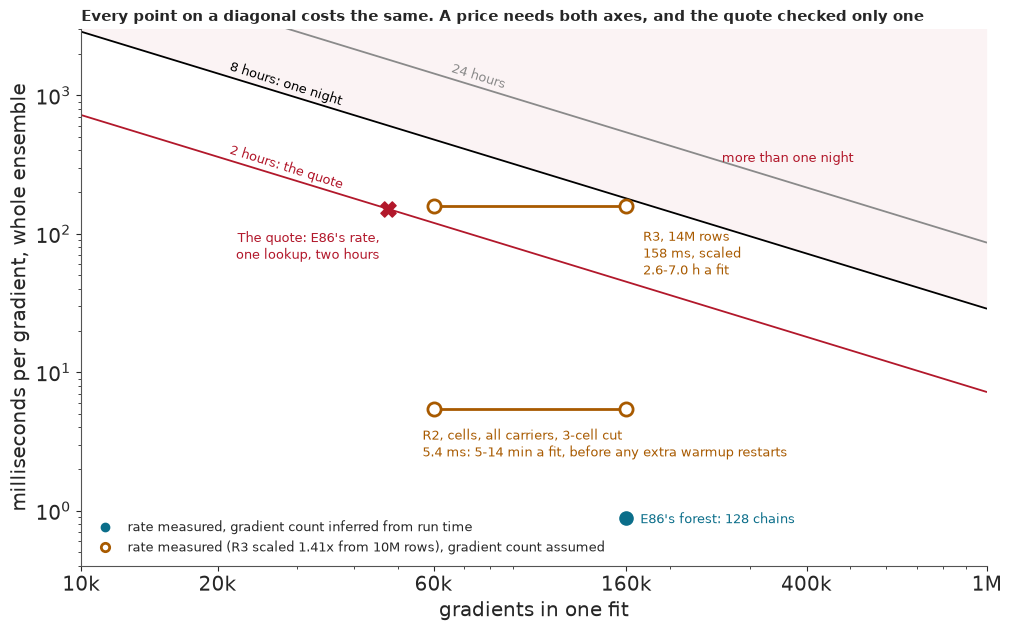

In [3]:
ROWS = 14_080_680  # all rows of 24 monthly files
CHAINS = 32
LOOKUPS = 5  # carrier, flight, origin x day, destination x day, tail
E86_NS = 0.86e-3 / (128 * 20_000) * 1e9  # E86's rate per chain and cell
E86_TOTAL, E86_SAMPLING = 160_000, 27_161  # E86: about 137.6 s at 0.86 ms a gradient, and its stored sampling count
GRADIENTS = (60_000, E86_TOTAL)  # a plain assumption, and E86's whole run at 128 chains

cell_500k = jobs["p4_cell"]
cell_10m = jobs["p4_10m"]
ms_10m = cell_10m["rows"][0]["run_ms"]
rows_10m = cell_10m["shape"]["rows"]
ns_lookup = ms_10m * 1e6 / (CHAINS * rows_10m * LOOKUPS)
ms_14m = ms_10m * ROWS / rows_10m
ms_quote = E86_NS * CHAINS * ROWS / 1e6


def hours(ms, gradients, fits=1):
    return ms / 1e3 * gradients / 3600 * fits


by_month = pd.DataFrame(summary["by_month"])
month_totals = by_month["rows"].to_numpy()
fit_rows = {"24 months": [ROWS] * 3, "all earlier rows": [month_totals[:t].sum() for t in TARGETS],
            "12-month window": [month_totals[t - WINDOW:t].sum() for t in TARGETS]}
ms_window = ms_14m * np.mean(fit_rows["12-month window"]) / ROWS


quote = pd.DataFrame({"per gradient (ms)": [ms_quote, ms_14m],
                      "lookups a row": [1, LOOKUPS],
                      "ns per chain-lookup": [E86_NS, ns_lookup]},
                     index=["the contractor's sum, E86's rate", "this model, measured to 10M rows, scaled to 14M"])
print(quote.round(3).to_string())
price_rows = {f"{g // 1000}k gradients": {"one fit, 24 months (h)": hours(ms_14m, g),
                                          **{f"three fits, {k} (h)": sum(hours(ms_14m * r / ROWS, g) for r in v)
                                             for k, v in fit_rows.items()}} for g in GRADIENTS}
print(pd.DataFrame(price_rows).T.round(1).to_string())
print("Rows in each of the three fits:", {k: [f"{r / 1e6:.2f}M" for r in v] for k, v in fit_rows.items()})
two_hour_limit = 7200 / (ms_14m / 1e3)
print(f"Two hours needs at most {two_hour_limit:,.0f} gradients at {ms_14m:.0f} ms each, "
      f"{GRADIENTS[0] / two_hour_limit:.1f}x under 60k")
gradients_32 = E86_TOTAL - E86_SAMPLING + 4 * E86_SAMPLING
print(f"E86 sampled {E86_SAMPLING:,} of about {E86_TOTAL:,} gradients at 128 chains. The same ESS from 32 chains needs "
      f"about {gradients_32:,}: {hours(ms_14m, gradients_32):.1f} h a fit")

r2_gpu_ms = jobs["r2_gpu"]["rows"][0]["run_ms"]
print(f"The same 12 months: {ms_window:.0f} ms as rows, {r2_gpu_ms:.1f} ms as cells, {ms_window / r2_gpu_ms:.1f}x. "
      f"On all 24 months of rows against those cells it looks like {ms_14m / r2_gpu_ms:.0f}x.")
e86_gradients = E86_TOTAL
fig, ax = plt.subplots(figsize=(10, 6.2), layout="constrained")
g = np.geomspace(1e4, 1e6, 50)
budgets = ((2, "2 hours: the quote", ALARM, 8), (8, "8 hours: one night", "k", 8), (24, "24 hours", MUTED, 20))
for budget, label, colour, at in budgets:
    ax.plot(g, budget * 3600e3 / g, color=colour, lw=1.3)
    ax.annotate(label, (g[at], budget * 3600e3 / g[at]), rotation=-17.5, rotation_mode="anchor", color=colour,
                fontsize=9.5, xytext=(0, 5), textcoords="offset points")
ax.fill_between(g, 8 * 3600e3 / g, 1e5, color=ALARM, alpha=0.05, lw=0)
ax.plot(GRADIENTS, [ms_14m] * 2, "-", color=EXTRA, lw=2, zorder=2)
ax.scatter(GRADIENTS, [ms_14m] * 2, s=90, facecolor="w", edgecolor=EXTRA, lw=2, zorder=3)
ax.annotate(f"R3, 14M rows\n{ms_14m:.0f} ms, scaled\n{hours(ms_14m, 60_000):.1f}-{hours(ms_14m, 160_000):.1f} h a fit",
            (GRADIENTS[1], ms_14m), xytext=(12, -49), textcoords="offset points", color=EXTRA, fontsize=9.5)
ax.scatter([7200 / (ms_quote / 1e3)], [ms_quote], marker="X", s=120, color=ALARM, zorder=3)
ax.annotate("The quote: E86's rate,\none lookup, two hours", (7200 / (ms_quote / 1e3), ms_quote), xytext=(-6, -36),
            textcoords="offset points", color=ALARM, fontsize=9.5, ha="right")
ax.plot(GRADIENTS, [r2_gpu_ms] * 2, "-", color=EXTRA, lw=2, zorder=2)
ax.scatter(GRADIENTS, [r2_gpu_ms] * 2, s=90, facecolor="w", edgecolor=EXTRA, lw=2, zorder=3)
ax.annotate(f"R2, cells, all carriers, 3-cell cut\n{r2_gpu_ms:.1f} ms: "
            f"{hours(r2_gpu_ms, 60_000) * 60:.0f}-{hours(r2_gpu_ms, 160_000) * 60:.0f} min a fit, before any extra "
            "warmup restarts", (GRADIENTS[0], r2_gpu_ms), xytext=(-8, -34), textcoords="offset points",
            color=EXTRA, fontsize=9.5)
ax.scatter([e86_gradients], [jobs["p1_a"]["rows"][0]["run_ms"]], s=90, color=MEASURED, zorder=3)
ax.annotate("E86's forest: 128 chains", (e86_gradients, jobs["p1_a"]["rows"][0]["run_ms"]), xytext=(10, -4),
            textcoords="offset points", color=MEASURED, fontsize=9.5)
ax.set(xscale="log", yscale="log", xlim=(1e4, 1e6), ylim=(0.4, 3000), xlabel="gradients in one fit",
       ylabel="milliseconds per gradient, whole ensemble")
ax.set_xticks([1e4, 2e4, 6e4, 1.6e5, 4e5, 1e6], ["10k", "20k", "60k", "160k", "400k", "1M"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.annotate("more than one night", (2.6e5, 330), color=ALARM, fontsize=9.5)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=MEASURED, label="rate measured, gradient count inferred from run time"),
                   Line2D([], [], marker="o", ls="", markerfacecolor="w", markeredgecolor=EXTRA, markeredgewidth=2,
                          label="rate measured (R3 scaled 1.41x from 10M rows), gradient count assumed")], loc="lower left", fontsize=9)
ax.set_title("Every point on a diagonal costs the same. A price needs both axes, and the quote checked only one",
             loc="left", fontsize=11);

Each diagonal is one budget. The orange points use measured rates and assumed gradient counts,
which is why they are hollow, and R3's rate is also scaled 1.41x from 10M rows. The blue dot is
E86's measured rate at a count inferred from its run time. Moving right along a flat line is
where this quote is exposed: the rate is about right, but it only meets two hours left of the 60k
point, with a margin of 1.3x.

60,000 is a plain assumption, and nothing here measures it. The only real count in this notebook
comes from section 6, where nutpie spends about 60,000 gradients a chain on 5,000 parameters.
That is a different sampler, so it is a hint, and not a measurement of R3. 160,000 is E86's whole
run, inferred from its time, on a forest with 24,810 parameters, and only 27,161 of those
gradients were sampling. That count alone would be under the two-hour limit, but sampling alone
is not a fit. R3 has about 747,000 parameters.

160,000 is not a ceiling either. E86 ran 128 chains, and the price uses 32. Matching E86's
effective sample size with a quarter of the chains needs about 4x its sampling gradients, about
240,000 in all, or about 10.6 hours, which is over a night.

R2 sits far below R3, for two reasons. On the same 12 months, rows would take about 79 ms a
gradient and R2's cells take 5.4 ms, so **collapsing rows into cells is worth about 15x a
gradient**, with no hardware bought. The rest of the 29x between the two lines is 24 months of
rows against 12 months of cells, so it comes from dropping half the data, and collapsing does not
earn it.

## 2. The flights

The table comes from 24 monthly BTS files. Coverage is carriers with at least 0.5% of domestic
scheduled passenger revenue, so smaller regional operators are absent.

e87_flights: NumPy archive, not a table: open data.path() with np.load. One row per eligible flight x month cell, 494,547 in all: cell_flight, cell_month (0 is 2024-01), cell_n (operations, 10 or more), cell_late (more than 30 minutes late at arrival, or cancelled). One row per flight, 128,423: flight_carrier, flight_origin, flight_dest (most-used airports). A flight is a cluster of departures in the sense of 14 CFR 399.81(c), linked across months as the build script describes, not an official flight. Carrier, airport and flight codes are shuffled integers, with no labels, scheduled times or flight numbers. That removes names, not identity: anyone with the public files can match the codes back. `notice` holds the source notice.
  source: US DOT Bureau of Transportation Statistics, TranStats, Reporting Carrier On-Time Performance (1987-present), the 24 monthly files of 2024-2025. No licence or terms were found for this table, so only re-coded tables are kept, one of them row-level for o

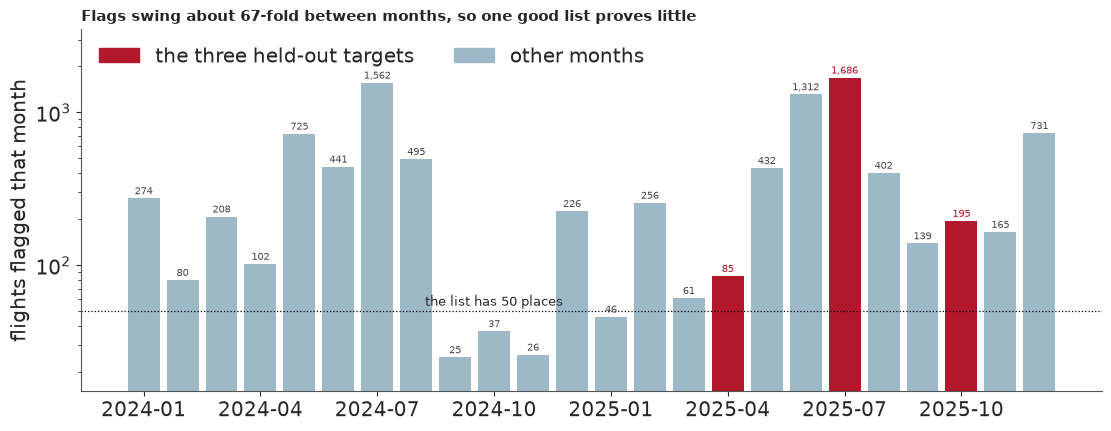

In [4]:
data.describe("e87_flights")
data.describe("e87_month_rows")
archive = np.load(data.path("e87_flights"))
flight_carrier, flight_origin, flight_dest = archive["flight_carrier"], archive["flight_origin"], archive["flight_dest"]
cells = pd.DataFrame({"flight": archive["cell_flight"], "month": archive["cell_month"].astype(int),
                      "n": archive["cell_n"].astype(int), "late": archive["cell_late"].astype(int)})
cells["rate"] = cells["late"] / cells["n"]
cells["flagged"] = cells["rate"] > 0.5
cells["carrier"] = flight_carrier[cells["flight"]]
same = (cells["flight"].to_numpy()[1:] == cells["flight"].to_numpy()[:-1]) & (
    cells["month"].to_numpy()[1:] == cells["month"].to_numpy()[:-1] + 1)
cells["state"] = np.r_[-1, np.where(same, cells["flagged"].to_numpy()[:-1].astype(int), -1)]  # last month: 1, 0, or not eligible
cells["last_rate"] = np.r_[np.nan, np.where(same, cells["rate"].to_numpy()[:-1], np.nan)]
print(f"{summary['rows']:,} rows in 24 monthly files, {summary['flight_months']:,} flight x month cells, "
      f"{summary['rows_per_cell']:.1f} rows a cell.")
print(f"Here: {len(cells):,} eligible cells (10 or more operations), {len(flight_carrier):,} flights, "
      f"{cells['flagged'].sum():,} flagged. Late or cancelled: {summary['late_share']:.1%} of rows.")
print(f"Diverted rows not counted late: {summary['diverted_not_late']:,}. "
      f"Target flights with no history: " + ", ".join(
          f"{TARGET_NAMES[t]} {1 - v['target_flights_with_history'] / v['target_flights']:.0%}"
          for t, v in zip(TARGETS, summary["linking"]["training_windows"].values())))

labels = pd.period_range("2024-01", periods=24, freq="M").astype(str)
fig, ax = plt.subplots(figsize=(11, 4.2), layout="constrained")
bar_colour = [ALARM if m in TARGETS else "#9db9c7" for m in by_month["month"]]
ax.bar(by_month["month"], by_month["flagged"], color=bar_colour, width=0.82)
ax.axhline(50, color="k", lw=0.9, ls=":")
ax.annotate("the list has 50 places", (9, 50), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
for m, flagged in zip(by_month["month"], by_month["flagged"]):
    ax.annotate(f"{flagged:,}", (m, flagged), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5,
                color=ALARM if m in TARGETS else "#4a4a4a")
ax.set(yscale="log", ylim=(15, 3500), ylabel="flights flagged that month", xticks=by_month["month"][::3])
ax.set_xticklabels(labels[::3])
ax.legend(handles=[Patch(color=ALARM, label="the three held-out targets"), Patch(color="#9db9c7", label="other months")],
          loc="upper left", ncols=2)
ax.set_title("Flags swing about 67-fold between months, so one good list proves little", loc="left", fontsize=11);

Two things follow. Four months had fewer flags than the list has places, so in a calm month a
perfect list of 50 would still hold flights nobody flagged. And the three test months differ by
20x, so a precision from one of them does not transfer to another.

These flights are short-lived as we link them: over all 259,558 linked flights, eligible or not,
the median lasts 2 months, and part of that is our linking, which splits some real flights
(section 8). 22-25% of target flights in two of the three months have no history at all (11% in
July). Any list here is partly a list of new flights.

## 3. What a gradient costs

Five models, five cost shapes. Row 5 is the row-level model's own gradient on one month of rows:
five lookups per row, whose reverse pass is a scatter-add. E86 had none of those, which is why
its rate might not transfer. Here is what the index pattern looks like. Each panel has one point
per row.

Adjacent rows share a flight 35% of the time, and a tail 6%


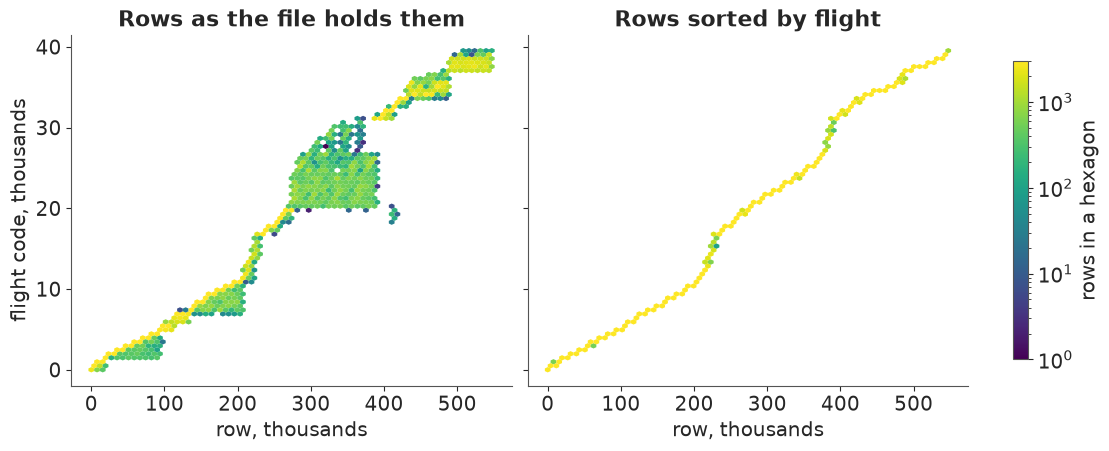

In [5]:
month = np.load(data.path("e87_month_rows"))
day = month["day"].astype(np.int64)
columns = {"carrier": month["carrier"].astype(np.int64), "flight": month["flight"].astype(np.int64),
           "origin_day": month["origin"] * 32 + day, "dest_day": month["dest"] * 32 + day,
           "tail": month["tail"].astype(np.int64)}
outcome = month["y"]
n_month = outcome.size
by_flight = np.argsort(columns["flight"], kind="stable")
adjacent = (columns["flight"][1:] == columns["flight"][:-1]).mean()
print(f"Adjacent rows share a flight {adjacent:.0%} of the time, and a tail "
      f"{(columns['tail'][1:] == columns['tail'][:-1]).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, layout="constrained")
for ax, order, title in zip(axes, (np.arange(n_month), by_flight), ("Rows as the file holds them", "Rows sorted by flight")):
    art = ax.hexbin(np.arange(n_month) / 1e3, columns["flight"][order] / 1e3, gridsize=70, cmap="viridis", norm=LogNorm(1, 3000),
                    mincnt=1, linewidths=0)
    ax.set(title=title, xlabel="row, thousands")
axes[0].set_ylabel("flight code, thousands")
fig.colorbar(art, ax=axes, shrink=0.85, label="rows in a hexagon");

The file visits flights in blocks and returns to them day after day. Sorting puts a flight's rows
side by side, and the plan said that should help a scatter. Now the timing. `time_gradient` waits
for the result, takes the best of three calls, and reports whether every output was finite. Rows
are timed on this machine in this run, and the GPU column is loaded.

bei_trees: Exact positions (x, y in metres) of the Beilschmiedia pendula trees in the 1000 x 500 m plot, with elevation (elev, m) and its gradient norm (grad) on a 5 m grid (yrow x xcol). Not a table: open data.path() with np.load.
  source: Hubbell & Foster (1983), Condit, Hubbell & Foster (1996) and Condit (1998), Barro Colorado Island forest dynamics plot, Panama; as shipped with the R package `spatstat.data` 3.1-9 (GPL >= 2), analysed by Moller & Waagepetersen (2007). CONVERTED from the R file by tools/build_e86_bei.py - keep the cached file.
  url:    https://raw.githubusercontent.com/cran/spatstat.data/master/data/bei.rda


bike_hour: Hourly rental counts 2011-2012 with weather and calendar covariates.
  source: Fanaee-T & Gama (2013), Capital Bikeshare (Washington DC), UCI ML Repository.
  url:    https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip


ff_industries12_daily: Daily % returns of 12 US industry portfolios since July 1926 (NoDur ... Other). The file holds TWO blocks, value-weighted then equal-weighted, each headed by a text line: keep the rows before the first non-date index. -99.99 marks missing.
  source: Kenneth R. French Data Library (Fama & French, CRSP), 12 industry portfolios; updated monthly.
  url:    https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/12_Industry_Portfolios_daily_CSV.zip


                            size      d   cpu_1    cpu_8  cpu ns/chain-row  gpu ms  gpu ns/chain-row  cpu / gpu
row                                                                                                            
1 forest, dense products    1250   2460   0.095    0.413            41.266   0.216             1.348     30.602
2 bikes, gammaln           17379     48   0.636    3.849            27.681   0.127             0.911     30.380
3 volatility, scan          5000   5003   0.138    0.311             7.776  62.820          1570.493      0.005
4 cells, R2 likelihood    246528  31503  32.845  284.673           144.341   5.403             0.685    210.771
5 rows, five lookups      547271  65218  11.304   96.099            21.949   2.724             0.622     35.278
Not matched: GPU row 1 is the 5 m lattice of 20,000 cells against 1,250 on the CPU, and GPU row 4 is 32 chains against 8. Rows 2, 3 and 5 are 8 chains on the same problem.
GPU row 3 by chains (ms): {8: 62.8, 32: 62.6

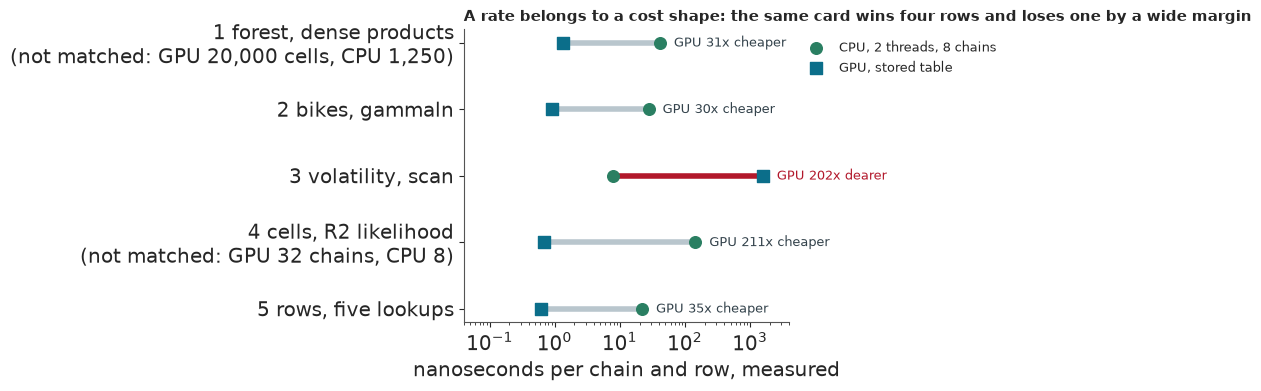

In [6]:
def field_model():
    """Row 1: E86's four-field forest at 20 m, as a flat JAX log density. A PyMC model, priced as it stands."""
    data.describe("bei_trees")
    raw = np.load(data.path("bei_trees"))
    cell, m_fine, m_smooth, half = 20.0, (25, 50), (20, 20), 800.0
    nx, ny = int(1000 / cell), int(500 / cell)
    y = np.histogram2d(raw["y"], raw["x"], bins=[ny, nx], range=[[0, 500], [0, 1000]])[0]
    k = int(cell / 5)

    def to_cells(v):
        c = 0.25 * (v[:-1, :-1] + v[1:, :-1] + v[:-1, 1:] + v[1:, 1:])
        c = c.reshape(ny, k, nx, k).mean((1, 3))
        return ((c - c.mean()) / c.std()).astype("float32")

    def basis(n, half_width, m):
        x = (np.arange(n) + 0.5) * cell
        x = x - x.mean()
        w = np.pi * np.arange(1, m + 1) / (2 * half_width)
        return (np.sqrt(1 / half_width) * np.sin(w[None, :] * (x[:, None] + half_width))).astype("float32"), w

    def density(w2, ell, nu):
        constant = {0.5: 2 * np.pi / ell, 1.5: 6 * np.pi * 3**1.5 / ell**3}[nu]
        return pt.sqrt(constant) * ((2 * nu) / ell**2 + w2) ** (-(nu + 1) / 2)

    elev, grad = to_cells(raw["elev"]), to_cells(np.log(raw["grad"]))
    Py, wy = basis(ny, 312.5, m_fine[0])
    Px, wx = basis(nx, 625.0, m_fine[1])
    Qy, vy = basis(ny, half, m_smooth[0])
    Qx, vx = basis(nx, half, m_smooth[1])
    w2 = (wy[:, None] ** 2 + wx[None, :] ** 2).astype("float32")
    v2 = (vy[:, None] ** 2 + vx[None, :] ** 2).astype("float32")
    pytensor.config.floatX = "float32"
    try:
        with pm.Model() as model:
            alpha = pm.Normal("alpha", np.log(30.0), 1.0)
            b_elev, b_grad = pm.Normal("b_elev", 0.0, 1.0), pm.Normal("b_grad", 0.0, 1.0)
            s_broad = pm.LogNormal("s_broad", np.log(0.7), 0.5)
            ell_broad = pm.LogNormal("ell_broad", np.log(120.0), 0.4)
            s_fine = pm.LogNormal("s_fine", np.log(0.7), 0.5)
            ell_fine = pm.LogNormal("ell_fine", np.log(20.0), 0.6)
            s_slope_elev = pm.LogNormal("s_slope_elev", np.log(0.5), 0.5)
            s_slope_grad = pm.LogNormal("s_slope_grad", np.log(0.5), 0.5)
            ell_slope = pm.LogNormal("ell_slope", np.log(200.0), 0.4)
            z_broad = pm.Normal("z_broad", 0.0, 1.0, shape=m_smooth)
            z_fine = pm.Normal("z_fine", 0.0, 1.0, shape=m_fine)
            z_elev = pm.Normal("z_elev", 0.0, 1.0, shape=m_smooth)
            z_grad = pm.Normal("z_grad", 0.0, 1.0, shape=m_smooth)
            smooth = lambda z, sd: Qy @ (sd * z) @ Qx.T
            sd_slope = density(v2, ell_slope, 1.5)
            eta = (alpha + (b_elev + smooth(z_elev, s_slope_elev * sd_slope)) * elev
                   + (b_grad + smooth(z_grad, s_slope_grad * sd_slope)) * grad
                   + smooth(z_broad, s_broad * density(v2, ell_broad, 1.5))
                   + Py @ (s_fine * density(w2, ell_fine, 0.5) * z_fine) @ Px.T + np.log(cell**2 / 1e4))
            pm.Poisson("y", pt.exp(eta), observed=y)
        logp = get_jaxified_logp(model)
        start = model.initial_point()
        q0, unravel = ravel_pytree([jnp.asarray(start[v.name]) for v in model.value_vars])
    finally:
        pytensor.config.floatX = "float64"
    return (lambda q: logp(unravel(q))), q0, y.size


def negative_binomial():
    """Row 2: bike hours, a design matrix and three gammaln a row."""
    data.describe("bike_hour")
    bike = data.load("bike_hour")
    X = pd.get_dummies(bike[["hr", "weekday", "mnth", "weathersit"]].astype(str), drop_first=True, dtype=float)
    X = np.c_[np.ones(len(X)), X.to_numpy(), bike[["temp", "hum", "windspeed"]].to_numpy(float)].astype(np.float32)
    counts, design = jnp.asarray(bike["cnt"].to_numpy(float), jnp.float32), jnp.asarray(X)

    def f(q):
        log_alpha, beta = q[0], q[1:]
        mu, alpha = jnp.exp(design @ beta), jnp.exp(log_alpha)
        lp = (jax_gammaln(counts + alpha) - jax_gammaln(alpha) - jax_gammaln(counts + 1)
              + alpha * (log_alpha - jnp.log(alpha + mu)) + counts * (jnp.log(mu) - jnp.log(alpha + mu)))
        return jnp.sum(lp) - 0.5 * jnp.sum(q * q) / 25.0

    return f, jnp.zeros(X.shape[1] + 1, jnp.float32).at[1].set(4.0), X.shape[0]


def stochastic_volatility():
    """Row 3: one industry's last 5,000 daily returns, a recursion through `jax.lax.scan`."""
    data.describe("ff_industries12_daily")
    ff = data.load("ff_industries12_daily").iloc[:, :12].apply(pd.to_numeric, errors="coerce")
    ff = ff.loc[[str(i).strip().isdigit() for i in ff.index]]
    r = ff.iloc[:, 0].to_numpy(float)
    r = r[(r > -99) & np.isfinite(r)][-5000:]
    returns = jnp.asarray(r / r.std(), jnp.float32)

    def f(q):
        mu, log_s, raw_phi, z = q[0], q[1], q[2], q[3:]
        s, phi = jnp.exp(log_s), jnp.tanh(raw_phi)

        def step(h, zt):
            h = mu + phi * (h - mu) + s * zt
            return h, h

        _, h = jax.lax.scan(step, mu, z)
        lp = -0.5 * (h + returns**2 * jnp.exp(-h))
        return jnp.sum(lp) - 0.5 * jnp.sum(z * z) - 0.5 * (mu**2 + log_s**2 + raw_phi**2)

    return f, jnp.zeros(returns.size + 3, jnp.float32).at[2].set(2.0), returns.size


def cell_model(target=TARGETS[0]):
    """Row 4: R2 on every carrier's cells, with a flight effect only for flights of 3 or more cells."""
    w = cells[(cells["month"] >= target - WINDOW) & (cells["month"] < target)]
    counts = np.bincount(w["flight"], minlength=flight_carrier.size)
    kept = np.flatnonzero(counts >= 3)
    own = counts[w["flight"]] >= 3
    code = np.where(own, np.searchsorted(kept, w["flight"]), kept.size)  # the last level is held at 0
    look = [np.unique(flight_carrier[w["flight"]], return_inverse=True)[1], np.unique(flight_origin[w["flight"]], return_inverse=True)[1],
            np.unique(flight_dest[w["flight"]], return_inverse=True)[1], w["month"].to_numpy() - (target - WINDOW)]
    sizes = [int(i.max()) + 1 for i in look] + [kept.size]
    cuts = np.cumsum(sizes)[:-1]
    look = [jnp.asarray(i, jnp.int32) for i in look + [code]]
    n, k = jnp.asarray(w["n"].to_numpy(), jnp.float32), jnp.asarray(w["late"].to_numpy(), jnp.float32)

    def f(q):
        log_phi, rest = q[0], q[1:]
        parts = jnp.split(rest, cuts)
        parts[-1] = jnp.concatenate([parts[-1], jnp.zeros(1, q.dtype)])
        eta = sum(p[i] for p, i in zip(parts, look))
        phi, p = jnp.exp(log_phi), jax.nn.sigmoid(eta)
        a, b = p * phi, (1 - p) * phi
        lp = (jax_gammaln(k + a) + jax_gammaln(n - k + b) - jax_gammaln(n + a + b)
              + jax_gammaln(a + b) - jax_gammaln(a) - jax_gammaln(b))
        return jnp.sum(lp) - 0.5 * jnp.sum(rest * rest) - 0.5 * log_phi * log_phi

    return f, jnp.zeros(sum(sizes) + 1, jnp.float32).at[0].set(3.0), len(w)


def row_model(rows):
    """Row 5: Bernoulli-logit with five lookups, on these rows. Codes are remade, so d follows the rows."""
    codes = [np.unique(columns[k][rows], return_inverse=True)[1] for k in columns]
    sizes = [int(c.max()) + 1 for c in codes]
    cuts = np.cumsum(sizes)[:-1]
    look = [jnp.asarray(c, jnp.int32) for c in codes]
    y = jnp.asarray(outcome[rows], jnp.float32)

    def f(q):
        eta = sum(p[i] for p, i in zip(jnp.split(q, cuts), look))
        return jnp.sum(y * eta - jnp.logaddexp(0.0, eta)) - 0.5 * jnp.sum(q * q)

    return f, jnp.zeros(sum(sizes), jnp.float32), rows.size


def timed(row, f, q0, size, chains=(1, 8)):
    rows = time_gradient(f, q0, chains=chains, repeat=3, seed=87)
    assert all(r["finite"] for r in rows), row
    return {"row": row, "size": size, "d": int(q0.size), **{f"cpu_{r['chains']}": r["run_ms"] for r in rows}}


with stage("timing rows 1-5"):
    table = [timed("1 forest, dense products", *field_model()), timed("2 bikes, gammaln", *negative_binomial()),
             timed("3 volatility, scan", *stochastic_volatility()), timed("4 cells, R2 likelihood", *cell_model()),
             timed("5 rows, five lookups", *row_model(np.arange(n_month)))]
rows_cpu = pd.DataFrame(table).set_index("row")
best = lambda job: {r["chains"]: r["run_ms"] for r in job["rows"]}
gpu_8 = {"1 forest, dense products": (min(best(jobs["p1_a"])[8], best(jobs["p1_b"])[8]), 20_000, 8),
         "2 bikes, gammaln": (best(extra_gpu["row2"])[8], 17_379, 8),
         "3 volatility, scan": (best(extra_gpu["row3"])[8], 5_000, 8),
         "4 cells, R2 likelihood": (r2_gpu_ms, jobs["r2_gpu"]["shape"]["cells"], CHAINS),
         "5 rows, five lookups": (extra_gpu["row5_month"]["month_file"][0]["run_ms"], n_month, 8)}
rows_cpu["cpu ns/chain-row"] = rows_cpu["cpu_8"] * 1e6 / (8 * rows_cpu["size"])
rows_cpu["gpu ms"] = [v[0] for v in gpu_8.values()]
rows_cpu["gpu ns/chain-row"] = [v[0] * 1e6 / (v[1] * v[2]) for v in gpu_8.values()]
rows_cpu["cpu / gpu"] = rows_cpu["cpu ns/chain-row"] / rows_cpu["gpu ns/chain-row"]
print(rows_cpu.round(3).to_string())
print("Not matched: GPU row 1 is the 5 m lattice of 20,000 cells against 1,250 on the CPU, and GPU row 4 is 32 chains against "
      "8. Rows 2, 3 and 5 are 8 chains on the same problem.")
print("GPU row 3 by chains (ms):", {k: round(v, 1) for k, v in best(extra_gpu["row3"]).items()})
row3_128 = best(extra_gpu["row3"])[128] * 1e6 / (128 * 5_000)
print(f"Row 3 at 128 chains costs {row3_128:.0f} ns per chain-row on the card, "
      f"{row3_128 / rows_cpu.loc['3 volatility, scan', 'cpu ns/chain-row']:.0f}x the CPU's 8-chain rate.")
month_by_chains = {r["chains"]: r["run_ms"] for r in extra_gpu["row5_month"]["month_file"]}
chain_saving = (month_by_chains[8] / 8) / (month_by_chains[32] / 32)
print(f"Row 5 on the card: cost per chain falls {chain_saving:.2f}x from 8 to 32 chains, so row 4's ratio is flattered "
      f"by about that much: about {rows_cpu.loc['4 cells, R2 likelihood', 'cpu / gpu'] / chain_saving:.0f}x if row 4 behaves like row 5.")

fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
order = rows_cpu.index[::-1]
UNMATCHED = {"1 forest, dense products": "1 forest, dense products\n(not matched: GPU 20,000 cells, CPU 1,250)",
             "4 cells, R2 likelihood": "4 cells, R2 likelihood\n(not matched: GPU 32 chains, CPU 8)"}
for i, row in enumerate(order):
    c, g = rows_cpu.loc[row, ["cpu ns/chain-row", "gpu ns/chain-row"]]
    ax.plot([c, g], [i, i], color=ALARM if g > c else "#b9c6cd", lw=4, solid_capstyle="round", zorder=1)
    ax.annotate(f"GPU {c / g:.0f}x cheaper" if c > g else f"GPU {g / c:.0f}x dearer", (max(c, g), i), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=9, color=ALARM if g > c else "#33424b")
ax.scatter(rows_cpu.loc[order, "cpu ns/chain-row"], range(5), s=70, marker="o", color=CALM, zorder=2, label="CPU, 2 threads, 8 chains")
ax.scatter(rows_cpu.loc[order, "gpu ns/chain-row"], range(5), s=70, marker="s", color=MEASURED, zorder=2, label="GPU, stored table")
ax.set(xscale="log", yticks=range(5), xlim=(0.04, 4000), xlabel="nanoseconds per chain and row, measured")
ax.set_yticklabels([UNMATCHED.get(row, row) for row in order])
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.set_title("A rate belongs to a cost shape: the same card wins four rows and loses one by a wide margin", loc="left", fontsize=11);

**A rate belongs to a cost shape.** On four rows the card costs 22-220x less per chain and row
than 2 CPU threads. That range is not like for like. Rows 2 and 5 are matched, at about 22-37x.
Row 1 sets the 5 m lattice of 20,000 cells on the card against 1,250 cells on the CPU. Row 4 sets
32 GPU chains against 8 CPU chains, and row 5 shows the card's cost per chain falling about 1.76x
between those counts, so the 220x top is flattered: about 120x if row 4 behaves like row 5.

On row 3, the `scan`, the card costs about 190-220x more at 8 chains, and its time does not move
with chains: 63 ms at 8, 32 and 128. So the gap shrinks as chains rise, to about 12-13x at 128
chains against the CPU's 8-chain rate. A recursion runs step by step on the card, so one rate
cannot price all five rows. Row 4 at about 140-150 ns is the dearest row on the CPU. Its six
`gammaln` are the likely reason, though they were not timed alone. The CPU side is 2 threads, by
the machine's rules, so this table shows where the time goes. It does not show that a GPU beats a
well-run CPU.

### The first failure: our own plan

We expected the reverse pass of a lookup to be a slow scatter, and planned to fix it by sorting.
So the next cell climbs from one day of rows to a month, sorted and unsorted, and fits a cost
law. The right panel loads a different test from the card: one lookup at 10 million rows, where
the climb has five lookups.

order         file        sorted        
chains           1      8      1       8
days rows                               
1    17265    0.32   1.61   0.31    1.64
3    54762    0.70   3.98   0.68    3.63
7    126699   2.71  21.81   2.65   20.70
14   248897   5.17  44.42   5.10   40.24
31   547271  11.36  97.51  11.32  100.66
Power law from 1, 3 and 7 days: {'slope': np.float64(1.28), 'predicted_ms': np.float64(111.81), 'measured_ms': np.float64(97.51), 'error': np.float64(0.15)}
Same, sorted:                   {'slope': np.float64(1.24), 'predicted_ms': np.float64(97.86), 'measured_ms': np.float64(100.66), 'error': np.float64(-0.03)}
From 1 and 3 days only:         {'slope': np.float64(0.78), 'predicted_ms': np.float64(24.17), 'measured_ms': np.float64(97.51), 'error': np.float64(-0.75)}
Straight line from the week alone: 94.2 ms against 97.5 ms measured


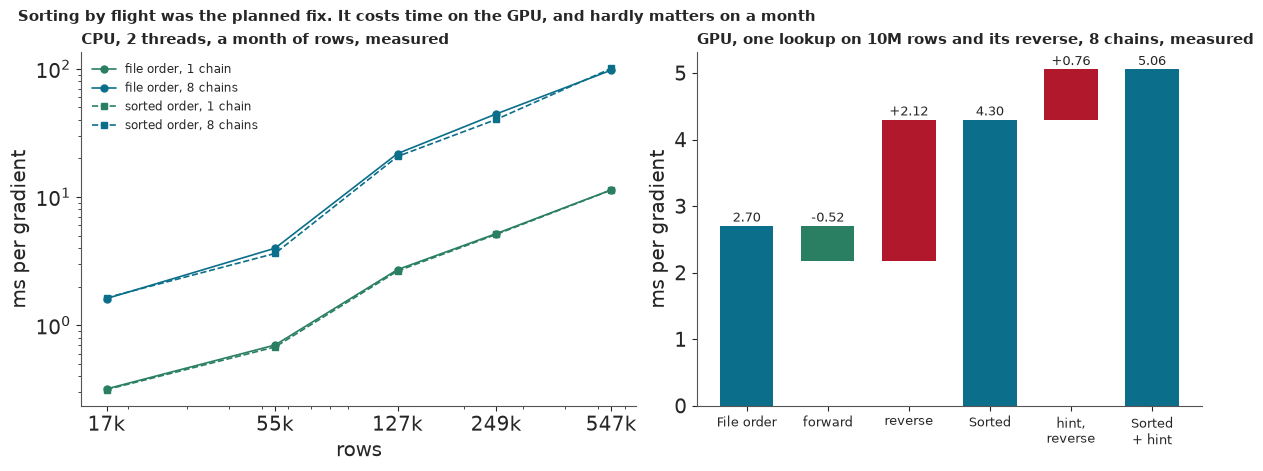

In [7]:
def run_ladder(days=(1, 3, 7, 14, 31)):
    """Row 5 on the first `d` days of the month, in file order and sorted by flight, at 1 and 8 chains."""
    out = []
    for last in days:
        rows = np.flatnonzero(day <= last)
        for name, used in (("file", rows), ("sorted", rows[np.argsort(columns["flight"][rows], kind="stable")])):
            f, q0, size = row_model(used)
            for r in time_gradient(f, q0, chains=(1, 8), repeat=3, seed=87):
                out.append({"days": last, "order": name, "chains": r["chains"], "rows": size, "d": int(q0.size), "ms": r["run_ms"]})
    return pd.DataFrame(out)


with stage("row 5 ladder"):
    ladder = run_ladder()
print(ladder.pivot_table(index=["days", "rows"], columns=["order", "chains"], values="ms").round(2).to_string())


def predict_month(fit_days=(1, 3, 7), chains=8, order="file"):
    """Fit a power law on small subsets, and predict the whole month's time."""
    part = ladder[(ladder["chains"] == chains) & (ladder["order"] == order)].set_index("days")
    slope, level = np.polyfit(np.log(part.loc[list(fit_days), "rows"]), np.log(part.loc[list(fit_days), "ms"]), 1)
    predicted = np.exp(level + slope * np.log(part.loc[31, "rows"]))
    return {"slope": slope, "predicted_ms": predicted, "measured_ms": part.loc[31, "ms"],
            "error": predicted / part.loc[31, "ms"] - 1}


print("Power law from 1, 3 and 7 days:", {k: round(v, 2) for k, v in predict_month().items()})
print("Same, sorted:                  ", {k: round(v, 2) for k, v in predict_month(order="sorted").items()})
print("From 1 and 3 days only:        ", {k: round(v, 2) for k, v in predict_month(fit_days=(1, 3)).items()})
week = ladder[(ladder["days"] == 7) & (ladder["order"] == "file") & (ladder["chains"] == 8)].iloc[0]
whole = ladder[(ladder["days"] == 31) & (ladder["order"] == "file") & (ladder["chains"] == 8)].iloc[0]
print(f"Straight line from the week alone: {week['ms'] * whole['rows'] / week['rows']:.1f} ms against {whole['ms']:.1f} ms measured")

p3 = {name: jobs[f"p3_{key}"]["10m"] for name, key in (("file", "unsorted_default"), ("sorted", "sorted_nohint_default"),
                                                      ("hint", "sorted_hint_default"))}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained", width_ratios=(1.1, 1))
ax = axes[0]
for (name, chains), part in ladder.groupby(["order", "chains"]):
    ax.plot(part["rows"], part["ms"], "o-" if name == "file" else "s--", color=MEASURED if chains == 8 else CALM, lw=1.2, ms=5,
            label=f"{name} order, {chains} chain{'s' if chains > 1 else ''}")
ax.set(xscale="log", yscale="log", xlabel="rows", ylabel="ms per gradient")
ax.set_title("CPU, 2 threads, a month of rows, measured", fontsize=10.5, loc="left")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xticks(sorted(ladder["rows"].unique()))
ax.legend(fontsize=8.5)
ax = axes[1]
steps = [("File order", p3["file"]["run_ms"], "total"),
         ("forward", p3["sorted"]["forward_ms"] - p3["file"]["forward_ms"], "step"),
         ("reverse", p3["sorted"]["reverse_extra_ms"] - p3["file"]["reverse_extra_ms"], "step"),
         ("Sorted", p3["sorted"]["run_ms"], "total"),
         ("hint,\nreverse", p3["hint"]["reverse_extra_ms"] - p3["sorted"]["reverse_extra_ms"], "step"),
         ("Sorted\n+ hint", p3["hint"]["run_ms"], "total")]
level = 0.0
for i, (label, value, kind) in enumerate(steps):
    if kind == "total":
        ax.bar(i, value, color=MEASURED, width=0.66)
        level = value
        ax.annotate(f"{value:.2f}", (i, value), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    else:
        ax.bar(i, value, bottom=level, color=ALARM if value > 0 else CALM, width=0.66)
        level += value
        ax.annotate(f"{value:+.2f}", (i, max(level, level - value)), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(range(len(steps)), [s[0] for s in steps], fontsize=9)
ax.set(ylabel="ms per gradient")
ax.set_title("GPU, one lookup on 10M rows and its reverse, 8 chains, measured", fontsize=10.5, loc="left")
fig.suptitle("Sorting by flight was the planned fix. It costs time on the GPU, and hardly matters on a month", x=0.01, ha="left", fontsize=11);

**The slow scatter did not appear, and the fix made things worse.** On the card, sorting cuts the
forward pass by 0.52 ms and adds 2.12 ms to the reverse pass, so a gradient goes from 2.70 to
4.30 ms, and passing JAX the sorted hint adds another 0.76 ms: 1.6-1.9x slower overall. We did
not find the cause. The gradients were checked against an exact NumPy answer, which clears a
wrong result. The plan's other suspect was the expander flag, an XLA option that changes how a
scatter is compiled. It compiled to the same program on file order, where the programs were
hashed, and it timed the same on sorted rows, where they were not.

On a month of rows with five lookups, sorting by flight changes nothing on the card (2.7 ms
either way at 8 chains) or on the CPU. Size and the number of lookups changed together between
those two tests, and sorting with five lookups at 10M rows was never measured, so the cause of
the difference is unknown. The lesson we planned, collapse, then sort, then buy, loses its middle
step. **Collapse first, then measure.**

A cost law needs a warning too. On the CPU, going from 3 days to 7 days multiplies rows by 2.3
and time by about 4-6, at 1 and at 8 chains, and it repeated in every build. We only partly know
why. A run pinned to one core, outside this notebook, removes the step at 1 chain, at about 15 ns
a row at every size and 8.3 ms on the month, faster than 2 threads. So at 1 chain the step is a
threading effect, and the CPU column of row 5 is not a clean 2-core rate. At 8 chains a step
remains between 6 and 7 days even on one core, and we do not know why. A power law fitted on 1, 3
and 7 days lands within about a fifth of the month, on either side, by luck, because it straddles
the step. Fitted on 1 and 3 days alone it misses the month by about 70-90%: see the printed line.
On the card, 500k to 10M rows ran at 0.074 and 0.070 ns per chain-lookup, so the last step to 14M
has evidence behind it. That evidence is two points on one card, and it says nothing about any
other.

## 4. The quote, and the walls behind it

Time is one wall. Memory and precision are the other two, and neither shows up in a rate.

            8 chains  16 chains  32 chains  64 chains  128 chains
0.5M rows       0.05       0.10       0.35       0.40        0.81
1.0M rows       0.10       0.20       0.40       0.81        1.61
5.0M rows       0.50       1.01       2.02       4.04        8.07
10.0M rows      1.01       2.02       4.04       8.07       16.15
14.1M rows      1.42       2.84       5.68      11.37       22.74
Measured: 500k x 32 = 0.35 GiB, 10M x 32 = 4.04 GiB. Usable VRAM 16.56 GiB.
Scaling from 10M would put 500k x 32 at 0.20 GiB, 1.7x too low. Both measured cells are at 32 chains.
The 3-cell cut keeps 30,789 of 72,386 flights, and 24% of cells lose their flight's own effect.
ChEES warmup's d x d table, GiB: {'R2 cut, d 31,503': 3.7, 'R2 every flight, d 73,100': 19.9, 'R3, d 747,000': 2078.7}
|logp| at the month's own rate: 263,495, float32 spacing there 0.031 nats. At 14M rows with this month's rate: 6,779,439, spacing 0.50 nats (arithmetic, not a test).


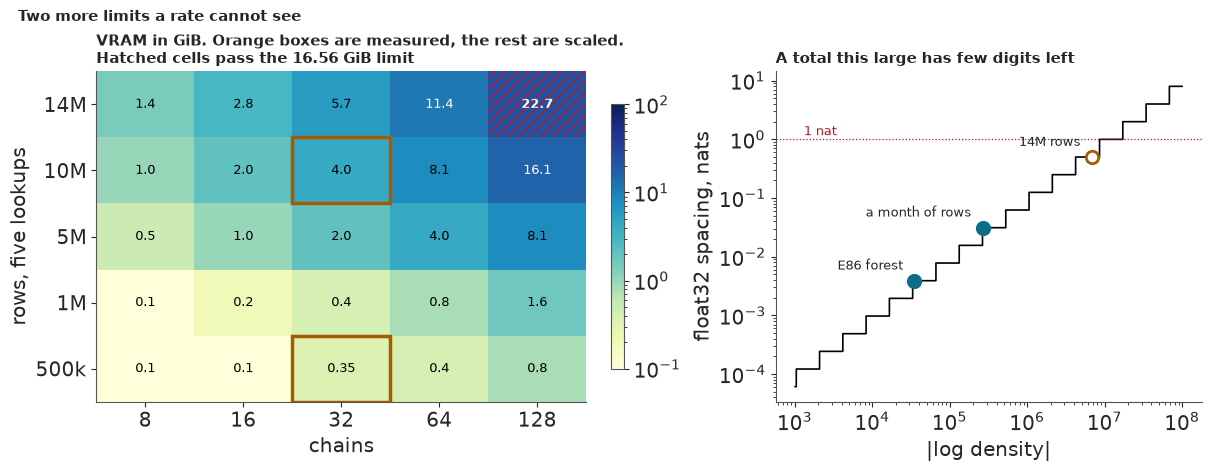

In [8]:
per_chain_row_gib = cell_10m["vram"]["peak_gb"] / (CHAINS * rows_10m)
grid_rows = np.array([500_089, 1e6, 5e6, 10_000_174, ROWS])
grid_chains = np.array([8, 16, 32, 64, 128])
vram = per_chain_row_gib * grid_rows[:, None] * grid_chains[None, :]
scaled_500k = vram[0, 2]
vram[0, 2] = cell_500k["vram"]["peak_gb"]  # the other measured cell: scaling from 10M misses it
LIMIT = jobs["p1_a"]["vram"]["limit_gb"]
print(pd.DataFrame(vram, index=[f"{r / 1e6:.1f}M rows" for r in grid_rows], columns=[f"{c} chains" for c in grid_chains]).round(2).to_string())
print(f"Measured: 500k x 32 = {cell_500k['vram']['peak_gb']:.2f} GiB, 10M x 32 = {cell_10m['vram']['peak_gb']:.2f} GiB. Usable VRAM {LIMIT:.2f} GiB.")
print(f"Scaling from 10M would put 500k x 32 at {scaled_500k:.2f} GiB, {vram[0, 2] / scaled_500k:.1f}x too low. "
      "Both measured cells are at 32 chains.")

window_counts = np.bincount(cells.loc[(cells["month"] >= TARGETS[0] - WINDOW) & (cells["month"] < TARGETS[0]), "flight"])
window_cells = cells[(cells["month"] >= TARGETS[0] - WINDOW) & (cells["month"] < TARGETS[0])]
flights_cut, flights_all = jobs["r2_gpu"]["shape"]["levels"]["flight_cut"], int((window_counts > 0).sum())
d_cut = jobs["r2_gpu"]["shape"]["d"]
d_all = d_cut + flights_all - flights_cut
R3_D = 747_000  # plans/large/E87.md section 12: 481k day cells, 260k flights, 6k tails
print(f"The 3-cell cut keeps {flights_cut:,} of {flights_all:,} flights, and "
      f"{(window_counts[window_cells['flight']] < 3).mean():.0%} of cells lose their flight's own effect.")
print("ChEES warmup's d x d table, GiB:", {name: round(d * d * 4 / 2**30, 1) for name, d in
                                          ((f"R2 cut, d {d_cut:,}", d_cut), (f"R2 every flight, d {d_all:,}", d_all), (f"R3, d {R3_D:,}", R3_D))})
per_row = stats.bernoulli.logpmf(outcome, outcome.mean()).mean()
logp_month, logp_14m = abs(per_row) * n_month, abs(per_row) * ROWS
spacing = lambda x: float(np.spacing(np.float32(x)))
print(f"|logp| at the month's own rate: {logp_month:,.0f}, float32 spacing there {spacing(logp_month):.3f} nats. "
      f"At 14M rows with this month's rate: {logp_14m:,.0f}, spacing {spacing(logp_14m):.2f} nats (arithmetic, not a test).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained", width_ratios=(1.15, 1))
ax = axes[0]
mesh = ax.imshow(vram, cmap="YlGnBu", norm=LogNorm(0.1, 100), origin="lower", aspect="auto")
for i in range(grid_rows.size):
    for j in range(grid_chains.size):
        over = vram[i, j] > LIMIT
        ax.text(j, i, f"{vram[i, j]:.2f}" if (i, j) == (0, 2) else f"{vram[i, j]:.1f}", ha="center", va="center", fontsize=9.5,
                color="w" if vram[i, j] > 10 else "k", weight="bold" if over else None)
        if over:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///", edgecolor=ALARM, lw=0))
for i in (0, 3):
    ax.add_patch(Rectangle((1.5, i - 0.5), 1, 1, fill=False, edgecolor=EXTRA, lw=2.5))
ax.set(xticks=range(5), yticks=range(5), xlabel="chains", ylabel="rows, five lookups")
ax.set_xticklabels(grid_chains)
ax.set_yticklabels(["500k", "1M", "5M", "10M", "14M"])
ax.grid(False)
ax.set_title(f"VRAM in GiB. Orange boxes are measured, the rest are scaled.\nHatched cells pass the {LIMIT:.2f} GiB limit", fontsize=10.5, loc="left")
fig.colorbar(mesh, ax=ax, shrink=0.8)
ax = axes[1]
x = np.logspace(3, 8, 600)
ax.step(x, np.spacing(x.astype(np.float32)), where="post", color="k", lw=1.2)
points = [("E86 forest", abs(jobs["p1_a"]["logp_at_start"]), True), ("a month of rows", logp_month, True), ("14M rows", logp_14m, False)]
for name, value, known in points:
    ax.scatter([value], [spacing(value)], s=80, color=MEASURED if known else "w", edgecolor=MEASURED if known else EXTRA, lw=2, zorder=3)
    ax.annotate(name, (value, spacing(value)), xytext=(-8, 8), textcoords="offset points", ha="right", fontsize=9.5)
ax.axhline(1.0, color=ALARM, lw=0.9, ls=":")
ax.annotate("1 nat", (1.3e3, 1.0), xytext=(0, 3), textcoords="offset points", color=ALARM, fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="|log density|", ylabel="float32 spacing, nats")
ax.set_title("A total this large has few digits left", fontsize=10.5, loc="left")
fig.suptitle("Two more limits a rate cannot see", x=0.01, ha="left", fontsize=11);

Our plan drew the memory wall at 32 chains. The measured cells move it: 32 chains at 14M rows
need about 5.7 GiB, not 12-18, and at 14M only 128 chains go over the 16.56 GiB this card gives
JAX. Only the two orange cells are measured, both at 32 chains, and the rest are scaled from the
10M cell. That scaling misses the other measurement by about 1.7x, 0.2 against 0.35 GiB, so
memory is not proportional to rows at the small end, and scaling by chain count is untested. No
cell above 10M rows ran, and none failed, so the wall is arithmetic.

**A larger wall sits outside this grid.** The grid counts gradients only. E86's ChEES recipe, the
source of the 160,000, also keeps a d x d table during warmup (`m2` in blackjax's
`chees_adaptation`). At R3's 747,000 parameters that table is about 2,080 GiB. It is also why R2
had to be cut for ChEES: with every flight it is about 20 GiB, over the limit. With flight
effects kept only for flights of 3 or more cells it is 3.7 GiB, but only 30,789 of 72,386 flights
keep their own effect, and 24% of cells lose it, so the cut model is not the model fitted in
section 6. A private blackjax option, `_length_floor=False`, skips the table. It is untested
here, and its gradient count is unknown. So R3's price joins a gradient count from a path that
cannot run to a memory figure from a path with no count.

Precision is the unresolved one. At 14 million rows the total log density is near 6.8 million,
where neighbouring float32 numbers are 0.5 nats apart. That is the spacing, and the error of a
real sum was not measured: the check that would measure it was not run, and it cannot run on a
month, where the spacing is 0.03. Rounding of this size changes acceptance. It does not by itself
cause a divergence. **A row-level run must pass this test before anyone relies on its 7.0
hours.**

## 5. Two counting rules

The analyst's table comes first, because it may win. **R0** says a flight flagged last month will
be flagged again, with a rate from pairs of months in the window. **R1** counts each flight's
late operations over the window, shrinks them towards a Beta prior fitted to its carrier, and
predicts next month with a beta-binomial. Both run on all carriers. Neither needs a sampler.

### The second failure: a rate that never moves

The first R1 treated a flight's rate as the same every month. With a year of history its Beta is
tight, so a flight running at 20% gets a tiny chance of passing 50%, and whole months do not
behave like that. The fix adds one number per carrier, a month-to-month concentration estimated
in the window. Only the fixed version is a rung, a choice made before any score was read.

target               2025-04    2025-07    2025-10
flights            19770.000  21791.000  20803.000
flagged               85.000   1686.000    195.000
R0 expected          290.585    560.784    366.552
R1 first expected     98.582    451.136    247.040
R1 expected          155.518    548.446    324.834
R0 score              -0.032     -0.276     -0.051
R1 first score        -0.026     -0.329     -0.048
R1 score              -0.026     -0.270     -0.048
R0 top 50 hits         4.000     36.000     20.000
R1 top 50 hits         9.000     35.000      9.000


Top 50 hits from last month's file alone: {'2025-04': {'R0': 4, 'R1': 6}, '2025-07': {'R0': 35, 'R1': 31}, '2025-10': {'R0': 15, 'R1': 6}}
Flights in R1's look-ahead top 50 that were not eligible the month before: {'2025-04': 14, '2025-07': 2, '2025-10': 27}


         R0 hits  R1 hits  R0 hits, last month's file  R1 hits, last month's file  R0 score  R1 score
target                                                                                               
2025-01        1        2                           1                           1    -0.027    -0.020
2025-02       14        6                          16                           5    -0.068    -0.065
2025-03        7        4                           6                           4    -0.027    -0.020
2025-04        4        9                           4                           6    -0.032    -0.026
2025-05       21       21                          15                          12    -0.101    -0.101
2025-06       22       23                          14                           8    -0.266    -0.276
2025-07       36       35                          35                          31    -0.276    -0.270
2025-08       12       13                          10                          12 

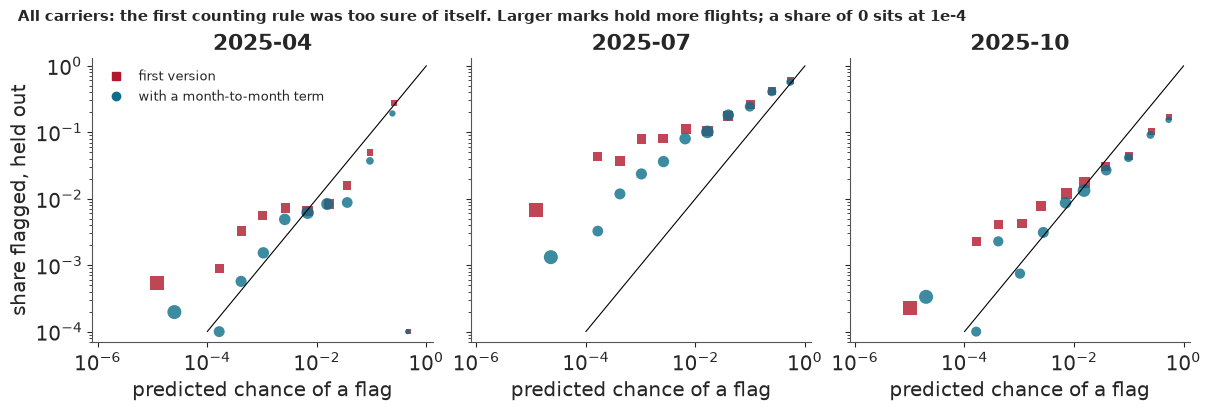

In [9]:
def window(target, months=WINDOW):
    return (cells["month"] >= target - months) & (cells["month"] < target)


def targets_of(target, carrier=None):
    part = cells[cells["month"] == target]
    return part if carrier is None else part[part["carrier"] == carrier]


def above_half(a, b, n):
    """P(Y > n / 2) for Y ~ BetaBinomial(n, a, b), exact, one value of n at a time."""
    a, b, n = np.asarray(a, float), np.asarray(b, float), np.asarray(n)
    out = np.zeros(n.size)
    for size in np.unique(n):
        k = np.arange(size // 2 + 1, size + 1)
        rows = n == size
        choose = gammaln(size + 1) - gammaln(k + 1) - gammaln(size - k + 1)
        out[rows] = np.exp(choose + betaln(a[rows, None] + k, b[rows, None] + size - k) - betaln(a[rows, None], b[rows, None])).sum(axis=1)
    return out


def r0_forecast(target, carrier=None, future=None):
    """Persistence, with a rate from pairs of months inside the window."""
    past = cells[window(target)]
    rate = past.groupby("state")["flagged"].agg(["sum", "size"])
    rate = (rate["sum"] + 0.5) / (rate["size"] + 1)
    part = targets_of(target, carrier) if future is None else future
    return part["state"].map(rate).to_numpy()


def r1_forecast(target, carrier=None, month_term=True, months=WINDOW, future=None):
    """Beta prior per carrier by moments, conjugate update, beta-binomial next month.

    `month_term=False` is the first version: it treats a flight's rate as the same every month.
    `months` shortens the history, and `future` replaces the flights being forecast.
    """
    train = cells[window(target, months)]
    totals = train.groupby("flight")[["n", "late"]].sum()
    totals["carrier"] = flight_carrier[totals.index]
    future = targets_of(target) if future is None else future
    out = pd.Series(0.0, index=future.index)
    for c, part in future.groupby("carrier"):
        mine = totals[totals["carrier"] == c]
        rate = mine["late"] / mine["n"]
        m = rate.mean()
        between = max(rate.var() - (m * (1 - m) / mine["n"]).mean(), 1e-4)
        strength = max(m * (1 - m) / between - 1, 2.0)
        a0, b0 = m * strength, (1 - m) * strength
        late, n = part["flight"].map(mine["late"]).fillna(0).to_numpy(), part["flight"].map(mine["n"]).fillna(0).to_numpy()
        mean, spread = (a0 + late) / (a0 + b0 + n), a0 + b0 + n
        if month_term:
            seen = train[train["carrier"] == c]
            r = ((a0 + seen["flight"].map(mine["late"])) / (a0 + b0 + seen["flight"].map(mine["n"]))).to_numpy()
            excess = np.mean((seen["rate"].to_numpy() - r) ** 2 - r * (1 - r) / seen["n"].to_numpy())
            kappa = max(np.mean(r * (1 - r)) / max(excess, 1e-4) - 1, 2.0)
            spread = 1 / (1 / spread + 1 / kappa)
        out[part.index] = above_half(mean * spread, (1 - mean) * spread, part["n"].to_numpy())
    return out.to_numpy() if carrier is None else out[future["carrier"].to_numpy() == carrier].to_numpy()


def log_score(p, flagged):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.where(flagged, np.log(p), np.log1p(-p))


def tie_break(part, salt):
    """Ranks tie under R0: last month's rate decides, then a fixed draw."""
    noise = np.random.default_rng([RANDOM_SEED, salt]).random(len(part))
    return part["last_rate"].fillna(-1).to_numpy() + 1e-6 * noise


def top(p, k, tie=None):
    return np.lexsort((-(np.zeros(p.size) if tie is None else tie), -p))[:k]


with stage("R0 and R1, all carriers"):
    national = {}
    for t in TARGETS:
        part = targets_of(t)
        began = time.perf_counter()
        r0 = r0_forecast(t)
        r0_s = time.perf_counter() - began
        began = time.perf_counter()
        r1 = r1_forecast(t)
        r1_s = time.perf_counter() - began
        national[t] = {"table": part, "R0": r0, "R1": r1, "R1 first": r1_forecast(t, month_term=False), "seconds": {"R0": r0_s, "R1": r1_s}}

rows = []
for t, f in national.items():
    flagged = f["table"]["flagged"].to_numpy()
    tie = tie_break(f["table"], t)
    rows.append({"target": TARGET_NAMES[t], "flights": flagged.size, "flagged": int(flagged.sum()),
                 **{f"{k} expected": f[k].sum() for k in ("R0", "R1 first", "R1")},
                 **{f"{k} score": log_score(f[k], flagged).mean() for k in ("R0", "R1 first", "R1")},
                 "R0 top 50 hits": int(flagged[top(f["R0"], 50, tie)].sum()), "R1 top 50 hits": int(flagged[top(f["R1"], 50)].sum())})
national_table = pd.DataFrame(rows).set_index("target")
print(national_table.T.round(3).to_string())


def list_from_last_month(target, k=50):
    """Top k from last month's file alone: last month's eligible flights, at last month's operations."""
    last = cells[cells["month"] == target - 1].assign(state=lambda d: d["flagged"].astype(int), last_rate=lambda d: d["rate"])
    now = targets_of(target)
    flagged_flights, eligible_flights = set(now.loc[now["flagged"], "flight"]), set(now["flight"])
    lists = {"R0": last["flight"].to_numpy()[top(r0_forecast(target, future=last), k, tie_break(last, target))],
             "R1": last["flight"].to_numpy()[top(r1_forecast(target, future=last), k)]}
    return {r: sum(f in flagged_flights for f in v) for r, v in lists.items()}


live = {TARGET_NAMES[t]: list_from_last_month(t) for t in TARGETS}
print("Top 50 hits from last month's file alone:", live)
print("Flights in R1's look-ahead top 50 that were not eligible the month before:",
      {TARGET_NAMES[t]: int((f["table"]["state"].to_numpy()[top(f["R1"], 50)] == -1).sum()) for t, f in national.items()})
rolling = []
for t in range(WINDOW, 24):
    part, r0, r1 = targets_of(t), r0_forecast(t), r1_forecast(t)
    flagged = part["flagged"].to_numpy()
    last_month = list_from_last_month(t)
    rolling.append({"target": labels[t], "R0 hits": int(flagged[top(r0, 50, tie_break(part, t))].sum()), "R1 hits": int(flagged[top(r1, 50)].sum()),
                    "R0 hits, last month's file": last_month["R0"], "R1 hits, last month's file": last_month["R1"],
                    "R0 score": log_score(r0, flagged).mean(), "R1 score": log_score(r1, flagged).mean()})
rolling = pd.DataFrame(rolling).set_index("target")
print(rolling.round(3).to_string())
print(f"12 origins. Hits: R0 {rolling['R0 hits'].sum()}, R1 {rolling['R1 hits'].sum()}; from last month's file R0 "
      f"{rolling.iloc[:, 2].sum()}, R1 {rolling.iloc[:, 3].sum()}. R0 led on hits in {(rolling['R0 hits'] > rolling['R1 hits']).sum()} months, "
      f"R1 in {(rolling['R1 hits'] > rolling['R0 hits']).sum()}; from last month's file R0 in {(rolling.iloc[:, 2] > rolling.iloc[:, 3]).sum()}, "
      f"R1 in {(rolling.iloc[:, 3] > rolling.iloc[:, 2]).sum()}. R1 had the better log score in {(rolling['R1 score'] > rolling['R0 score']).sum()}.")

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True, layout="constrained")
edges = np.r_[0, np.geomspace(1e-4, 1, 11)]
for ax, (t, f) in zip(axes, national.items()):
    flagged = f["table"]["flagged"].to_numpy()
    ax.plot([1e-4, 1], [1e-4, 1], color="k", lw=0.8)
    for key, colour, marker in (("R1 first", ALARM, "s"), ("R1", MEASURED, "o")):
        bin_of = np.digitize(f[key], edges[1:-1])
        shown = [(f[key][bin_of == b].mean(), flagged[bin_of == b].mean(), (bin_of == b).sum()) for b in np.unique(bin_of)]
        x, y, size = map(np.array, zip(*shown))
        ax.scatter(x, np.maximum(y, 1e-4), s=12 + 90 * np.sqrt(size / size.max()), color=colour, marker=marker, alpha=0.8, lw=0, label=key)
    ax.set(xscale="log", yscale="log", title=TARGET_NAMES[t], xlim=(8e-7, 1.3), ylim=(7e-5, 1.3), xlabel="predicted chance of a flag")
axes[0].set_ylabel("share flagged, held out")
axes[0].legend(handles=[Line2D([], [], marker="s", ls="", color=ALARM, label="first version"),
                        Line2D([], [], marker="o", ls="", color=MEASURED, label="with a month-to-month term")], loc="upper left", fontsize=9)
fig.suptitle("All carriers: the first counting rule was too sure of itself. Larger marks hold more flights; a share of 0 sits at 1e-4",
             x=0.01, ha="left", fontsize=11);

Perfect forecasts sit on the diagonal. Both versions sit above it at the low end, where the first
version promised less than one flag in 10,000 flights and saw far more. The fix helps most in
July, the worst month, taking the score from -0.329 to -0.270, and it leaves April and October
almost unchanged. It is not free: expected flags in the calm months rise further above the truth,
156 against 85 and 325 against 195, and July is still far short, 548 against 1,686. Neither
version foresaw a month that bad.

Neither rule wins the national top 50: R0 held 4, 36 and 20 flagged flights, and R1 held 9, 35
and 9. At a base rate of 0.4-8%, random lists would hold 0.2 to 3.9. That is the analyst's case,
for under a second of machine time.

Those counts lean on the target month's own schedule. A real list has only last month's file, so
it must rank last month's eligible flights at last month's operations. Built that way R0 held 4,
35 and 15 and R1 held 6, 31 and 6. Up to 27 of R1's look-ahead 50 were flights that were not
eligible the month before, which a real list could not name. Over all 12 months with a full
window, the two are level when they can see the target month's schedule: 158 hits against 147,
with R0 ahead in 5 months and R1 in 6. From last month's file alone R0 leads, 130 hits against
103, ahead in 7 months against 4. R1 still has the better log score in 11 of 12. So R0 ranks a
list better, and R1 states a chance better.

## 6. R2 on one carrier

R2 models each flight x month cell. On the logit scale, a flight's late rate is the carrier's
level plus effects for origin, destination, flight and month, and a beta-binomial `phi` carries
what is left between months:

$$\text{late}_{ft} \sim \text{BetaBinomial}\big(n_{ft},\ p_{ft}\phi,\ (1-p_{ft})\phi\big), \quad
\text{logit}\, p_{ft} = a + \sigma_o z_{o[f]} + \sigma_d z_{d[f]} + \sigma_f z_f + m_t .$$

Sds are LogNormal, since E86 saw half-normal priors on sds run away under MEADS, and the month
effect is a `pm.ZeroSumNormal`. The carrier is the 8th of 15 by cells before the first test
month, chosen by size alone. It is one carrier, so the plan's carrier term drops out. Every
eligible flight it ran in the window is in the model.

In [10]:
sizes = np.bincount(cells.loc[window(TARGETS[0]), "carrier"], minlength=15)
CARRIER = int(np.argsort(-sizes)[7])  # 8th of 15 by eligible cells before the first target: chosen by size alone
print(f"The carrier holds {sizes[CARRIER] / sizes.sum():.1%} of the eligible cells in the first window.")
typical = []
for t in TARGETS:
    seen = cells[window(t)]
    for name, part, group in (("this carrier", targets_of(t, CARRIER), seen[seen["carrier"] == CARRIER]), ("all carriers", targets_of(t), seen)):
        typical.append({"target": TARGET_NAMES[t], "group": name, "window cells per flight": len(group) / group["flight"].nunique(),
                        "target flights with no history": 1 - part["flight"].isin(group["flight"]).mean(),
                        "flags on flights not eligible last month": f"{int((part['flagged'] & (part['state'] == -1)).sum())} of {int(part['flagged'].sum())}"})
print(pd.DataFrame(typical).set_index(["target", "group"]).round(2).to_string())


def r2_cells(target, carrier=CARRIER):
    w = cells[window(target) & (cells["carrier"] == carrier)]
    return w["flight"].to_numpy(), w["month"].to_numpy() - (target - WINDOW), w["n"].to_numpy(), w["late"].to_numpy()


def r2_model(f, m, n, k):
    """R2: late or cancelled in a flight x month cell, beta-binomial, flight effects written non-centred."""
    flights, fi = np.unique(f, return_inverse=True)
    origins, oi = np.unique(flight_origin[flights], return_inverse=True)
    dests, di = np.unique(flight_dest[flights], return_inverse=True)
    coords = {"flight": np.arange(flights.size), "origin": np.arange(origins.size), "dest": np.arange(dests.size),
              "month": np.arange(WINDOW)}
    with pm.Model(coords=coords) as model:
        a = pm.Normal("a", -1.7, 1.0)
        s_o = pm.LogNormal("s_o", np.log(0.2), 0.6)
        s_d = pm.LogNormal("s_d", np.log(0.2), 0.6)
        s_f = pm.LogNormal("s_f", np.log(0.3), 0.6)
        s_m = pm.LogNormal("s_m", np.log(0.3), 0.6)
        z_o = pm.Normal("z_o", 0.0, 1.0, dims="origin")
        z_d = pm.Normal("z_d", 0.0, 1.0, dims="dest")
        z_f = pm.Normal("z_f", 0.0, 1.0, dims="flight")
        month_effect = pm.ZeroSumNormal("m", sigma=s_m, dims="month")
        phi = pm.LogNormal("phi", np.log(30.0), 1.0)
        base = a + s_o * z_o[oi] + s_d * z_d[di] + s_f * z_f
        p = pm.math.invlogit(base[fi] + month_effect[m])
        pm.BetaBinomial("y", n=n, alpha=p * phi, beta=(1 - p) * phi, observed=k)
    return model, flights, origins, dests, oi, di


# Prior predictive, in NumPy on the first window: do these priors allow what this carrier really did?
f_, m_, n_, k_ = r2_cells(TARGETS[0])
flights_, fi_ = np.unique(f_, return_inverse=True)
oi_ = np.unique(flight_origin[flights_], return_inverse=True)[1]
di_ = np.unique(flight_dest[flights_], return_inverse=True)[1]
draws = 400
prior_rng = np.random.default_rng(RANDOM_SEED)
scale = lambda mean: prior_rng.lognormal(np.log(mean), 0.6, size=(draws, 1))
eta = (prior_rng.normal(-1.7, 1.0, size=(draws, 1))
       + (scale(0.2) * prior_rng.normal(size=(draws, oi_.max() + 1)))[:, oi_]
       + (scale(0.2) * prior_rng.normal(size=(draws, di_.max() + 1)))[:, di_]
       + scale(0.3) * prior_rng.normal(size=(draws, flights_.size)))
eta = eta[:, fi_] + (scale(0.3) * prior_rng.normal(size=(draws, WINDOW)))[:, m_]
phi_prior = prior_rng.lognormal(np.log(30.0), 1.0, size=(draws, 1))
mean_prior = expit(eta)
y_prior = prior_rng.binomial(n_, prior_rng.beta(mean_prior * phi_prior, (1 - mean_prior) * phi_prior))
share_prior, flagged_prior = (y_prior.sum(1) / n_.sum()), ((y_prior / n_) > 0.5).mean(1)
print(f"Prior predictive: late share {np.quantile(share_prior, 0.05):.2f}-{np.quantile(share_prior, 0.95):.2f} "
      f"(observed {k_.sum() / n_.sum():.2f}); flagged cells {np.quantile(flagged_prior, 0.05):.1%}-{np.quantile(flagged_prior, 0.95):.1%} "
      f"(observed {(k_ / n_ > 0.5).mean():.1%})")
del eta, mean_prior, y_prior


def fit_r2(target, carrier=CARRIER, tune=TUNE, draws=DRAWS, seed=None):
    """One fit, with real gradient counts, and checks on a stand-in for the list as well as on parameters."""
    f, m, n, k = r2_cells(target, carrier)
    model, flights, origins, dests, oi, di = r2_model(f, m, n, k)
    began = time.perf_counter()
    compiled = nutpie.compile_pymc_model(model)
    trace = nutpie.sample(compiled, chains=4, cores=CHAINS_AT_ONCE, tune=tune, draws=draws, progress_bar=False, save_warmup=True,
                          store_mass_matrix=False, seed=RANDOM_SEED + target if seed is None else seed)
    seconds = time.perf_counter() - began
    post = trace.posterior
    keep = {v: post[v].values.reshape(-1, *post[v].shape[2:]) for v in ("a", "s_o", "s_d", "s_f", "s_m", "phi", "z_o", "z_d", "z_f")}
    base = keep["a"][:, None] + keep["s_o"][:, None] * keep["z_o"][:, oi] + keep["s_d"][:, None] * keep["z_d"][:, di] + keep["s_f"][:, None] * keep["z_f"]
    ranked = np.argsort(-base.mean(0))[:50]
    logit_mean = xr.Dataset({"x": (("chain", "draw", "flight"), base[:, ranked].reshape(4, draws, 50))})
    hyper = xr.Dataset({v: (("chain", "draw"), post[v].values) for v in ("a", "s_o", "s_d", "s_f", "s_m", "phi")})
    out = {"target": target, "flights": flights, "origins": origins, "dests": dests, "fi": np.unique(f, return_inverse=True)[1],
           "month": m, "n": n, "late": k, "keep": keep, "seconds": seconds,
           "stats": {"cells": n.size, "flights": flights.size, "d": sum(v.size for v in model.initial_point().values()),
                     "seconds": seconds, "gradients warmup": int(trace.warmup_sample_stats["n_steps"].values.sum()),
                     "gradients draws": int(trace.sample_stats["n_steps"].values.sum()),
                     "divergences": int(trace.sample_stats["diverging"].values.sum()),
                     "max r_hat top 50": float(np.asarray(az.rhat(logit_mean)["x"]).max()),
                     "min ESS top 50": float(np.asarray(az.ess(logit_mean, method="bulk")["x"]).min()),
                     "max r_hat hyper": max(float(az.rhat(hyper)[v]) for v in hyper.data_vars),
                     "min ESS hyper": min(float(az.ess(hyper, method="bulk")[v]) for v in hyper.data_vars)}}
    del trace, compiled, post, model, base, logit_mean
    gc.collect()
    return out


def effect(rng_, scale_, z, codes, known_codes):
    """Posterior effect for codes seen in training; a new draw from the same sd for those that were not."""
    position = np.searchsorted(known_codes, codes).clip(0, known_codes.size - 1)
    known = known_codes[position] == codes
    out = scale_[:, None] * rng_.normal(size=(scale_.size, codes.size))
    out[:, known] = scale_[:, None] * z[:, position[known]]
    return out


def r2_forecast(fit, carrier=CARRIER, seed=None):
    """Flag probabilities for next month's flights: the plain version, and the one that redraws the month."""
    target, keep = fit["target"], fit["keep"]
    part = targets_of(target, carrier)
    flight, n = part["flight"].to_numpy(), part["n"].to_numpy()
    rng_ = np.random.default_rng([RANDOM_SEED, target] if seed is None else [RANDOM_SEED, target, 1000 + seed])
    base = (keep["a"][:, None] + effect(rng_, keep["s_o"], keep["z_o"], flight_origin[flight], fit["origins"])
            + effect(rng_, keep["s_d"], keep["z_d"], flight_dest[flight], fit["dests"])
            + effect(rng_, keep["s_f"], keep["z_f"], flight, fit["flights"]))
    plain = stats.binom.sf(n // 2, n, expit(base))
    month_shock = keep["s_m"][:, None] * rng_.normal(size=(keep["s_m"].size, 1))
    mean = expit(base + month_shock)
    rate = rng_.beta(mean * keep["phi"][:, None], (1 - mean) * keep["phi"][:, None])
    redrawn = stats.binom.sf(n // 2, n, rate)
    count = (rng_.binomial(n, rate) / n > 0.5).sum(1)
    half = redrawn.shape[0] // 2
    return {"table": part, "plain": plain.mean(0), "R2": redrawn.mean(0), "count": count, "plain_count": (rng_.binomial(n, expit(base)) / n > 0.5).sum(1),
            "half_a": redrawn[:half].mean(0), "half_b": redrawn[half:].mean(0), "sum_by_draw": redrawn.sum(1)}


def replicated_checks(fit, sims=400):
    """Training-window checks that redraw every month and all overdispersion. Flights keep their fitted effects."""
    keep, rng_ = fit["keep"], np.random.default_rng([RANDOM_SEED, fit["target"], 1])
    sims = min(sims, keep["a"].size)
    pick = rng_.choice(keep["a"].size, sims, replace=False)
    oi = np.unique(flight_origin[fit["flights"]], return_inverse=True)[1]
    di = np.unique(flight_dest[fit["flights"]], return_inverse=True)[1]
    base = (keep["a"][pick, None] + keep["s_o"][pick, None] * keep["z_o"][pick][:, oi] + keep["s_d"][pick, None] * keep["z_d"][pick][:, di]
            + keep["s_f"][pick, None] * keep["z_f"][pick])
    mean = expit(base[:, fit["fi"]] + (keep["s_m"][pick, None] * rng_.normal(size=(sims, WINDOW)))[:, fit["month"]])
    phi = keep["phi"][pick, None]
    y = rng_.binomial(fit["n"], rng_.beta(mean * phi, (1 - mean) * phi))
    monthly = lambda late, flag: (np.array([late[..., fit["month"] == t].sum(-1) / fit["n"][fit["month"] == t].sum() for t in range(WINDOW)]),
                                  np.array([flag[..., fit["month"] == t].mean(-1) for t in range(WINDOW)]))
    rep_late, rep_flag = monthly(y, y / fit["n"] > 0.5)
    obs_late, obs_flag = monthly(fit["late"], fit["late"] / fit["n"] > 0.5)
    checks = {"month-to-month sd of late share": (rep_late.std(0), obs_late.std()), "worst month's flagged share": (rep_flag.max(0), obs_flag.max()),
              "mean flagged share": (rep_flag.mean(0), obs_flag.mean())}
    return {name: {"observed": o, "replicated 5%": np.quantile(r, 0.05), "replicated 95%": np.quantile(r, 0.95), "P(rep >= obs)": (r >= o).mean()}
            for name, (r, o) in checks.items()}, obs_flag


with stage("R2, one carrier, 3 fits"):
    forecasts, other_seeds, diagnostics, ppc, training_months = {}, {}, {}, {}, {}
    for t in TARGETS:
        fit = fit_r2(t)
        forecasts[t] = r2_forecast(fit)
        other_seeds[t] = [r2_forecast(fit, seed=s)["R2"] for s in range(12)]  # the same draws, other forecast noise
        diagnostics[TARGET_NAMES[t]] = fit["stats"]
        ppc[TARGET_NAMES[t]], training_months[t] = replicated_checks(fit)
        del fit
        gc.collect()
print(pd.DataFrame(diagnostics).round(3).to_string())
print(pd.concat({k: pd.DataFrame(v).T for k, v in ppc.items()}).round(3).to_string())

The carrier holds 3.9% of the eligible cells in the first window.
                      window cells per flight  target flights with no history flags on flights not eligible last month
target  group                                                                                                         
2025-04 this carrier                     1.91                            0.50                                  8 of 11
        all carriers                     3.41                            0.22                                 40 of 85
2025-07 this carrier                     1.73                            0.66                                 31 of 39
        all carriers                     3.20                            0.11                              297 of 1686
2025-10 this carrier                     1.65                            0.41                                   1 of 3
        all carriers                     3.31                            0.25                        

Prior predictive: late share 0.04-0.47 (observed 0.16); flagged cells 0.0%-42.9% (observed 3.2%)


                     2025-04     2025-07     2025-10
cells               9627.000    9313.000    8485.000
flights             5042.000    5398.000    5131.000
d                   5180.000    5535.000    5274.000
seconds              239.760     236.805     211.478
gradients warmup  121034.000  124592.000  119902.000
gradients draws   123248.000  124000.000  124000.000
divergences            0.000       0.000       0.000
max r_hat top 50       1.005       1.006       1.006
min ESS top 50      6120.818    6461.162    6251.626
max r_hat hyper        1.007       1.005       1.010
min ESS hyper        723.364     616.727     610.497
                                         observed  replicated 5%  replicated 95%  P(rep >= obs)
2025-04 month-to-month sd of late share     0.057          0.028           0.080          0.305
        worst month's flagged share         0.151          0.031           0.226          0.120
        mean flagged share                  0.030          0.012           0

This carrier is not typical, and size alone did not show that. It has 1.7-1.9 window cells a
flight against 3.2-3.4 nationally. 41-66% of its target flights have no history in the window, so
no fitted effect of their own, against 11-25% nationally, and 31 of July's 39 flags fell on
flights not eligible the month before. So the result below is less a test of flight history than
of how R2 treats new flights.

The priors allow a late share of 4-47% and flagged cells up to 43%, wide around the observed 16%
and 3%. The fits are clean on the parameters and on a stand-in for the list: 0 divergences, and
ESS above 6,000 on the logit mean of the 50 flights ranked highest in training and above 600 on
the hyperparameters. r_hat is at most about 1.01: the worst, an October hyperparameter at 1.0104,
strictly misses the plan's bar of 1.01. The stand-in is not the list itself, which ranks next
month's flights and redraws the month. Each fit spends about 60,000 gradients a chain in warmup
and sampling together.

The checks redraw all 12 months and all the overdispersion, keeping flights' fitted effects.
Observed values sit inside the 5-95% range on all three measures at all three origins, with P(rep
>= obs) from 0.10 to 0.51. Keeping fitted flight effects makes this a weak test: it says the
month spread is plausible, not that the forecasts are good. Only held-out months can say that.

### The third failure: forecasting an average month

The obvious forecast takes each flight's fitted effects, sets the month to its mean of zero, and
reads off the chance of passing 50%. Next month is a new month, so the right forecast draws a new
month effect from the fitted spread and new overdispersion, and new effects for flights and
airports the window never saw.

target                                 2025-04  2025-07  2025-10
flights                                675.000  593.000  500.000
flagged                                 11.000   39.000    3.000
first version, expected                  6.753    6.577    3.364
first version, score                    -0.078   -0.257   -0.030
redrawn, expected                       16.061   13.723    6.223
redrawn, 5%                              0.000    0.000    0.000
redrawn, 95%                            58.000   46.000   18.000
redrawn, score                          -0.077   -0.217   -0.033
list overlap, two halves of the draws    9.000   10.000   10.000


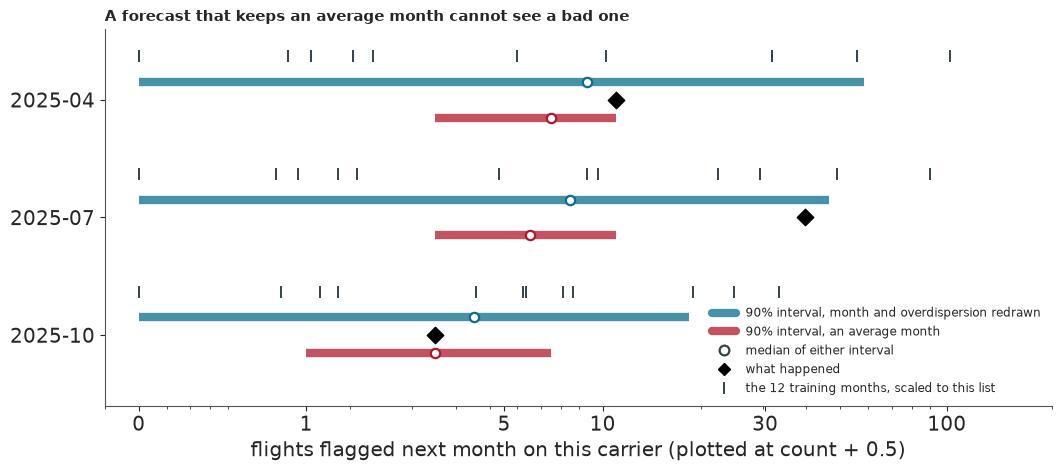

In [11]:
for t, f in forecasts.items():
    part = f["table"]
    f["R0"] = r0_forecast(t, CARRIER)
    f["R1"] = r1_forecast(t, CARRIER)
    f["tie"] = tie_break(part, t)
rows = []
for t, f in forecasts.items():
    flagged = f["table"]["flagged"].to_numpy()
    rows.append({"target": TARGET_NAMES[t], "flights": flagged.size, "flagged": int(flagged.sum()),
                 "first version, expected": f["plain"].sum(), "first version, score": log_score(f["plain"], flagged).mean(),
                 "redrawn, expected": f["R2"].sum(), "redrawn, 5%": np.quantile(f["count"], 0.05), "redrawn, 95%": np.quantile(f["count"], 0.95),
                 "redrawn, score": log_score(f["R2"], flagged).mean(),
                 "list overlap, two halves of the draws": len(set(top(f["half_a"], LIST_SIZE)) & set(top(f["half_b"], LIST_SIZE)))})
print(pd.DataFrame(rows).set_index("target").T.round(3).to_string())

fig, ax = plt.subplots(figsize=(10.5, 4.6), layout="constrained")
for row, (t, f) in enumerate(forecasts.items()):
    y = 2 - row
    total = len(f["table"])
    for shift, counts, colour in ((0.15, f["count"], MEASURED), (-0.15, f["plain_count"], ALARM)):
        low, mid, high = np.quantile(counts, [0.05, 0.5, 0.95])
        ax.plot([low + 0.5, high + 0.5], [y + shift] * 2, color=colour, lw=6, alpha=0.75, solid_capstyle="butt")
        ax.scatter([mid + 0.5], [y + shift], s=45, color="w", edgecolor=colour, lw=1.6, zorder=3)
    ax.scatter([f["table"]["flagged"].sum() + 0.5], [y], marker="D", s=70, color="k", zorder=4)
    ax.plot(training_months[t] * total + 0.5, np.full(WINDOW, y + 0.37), "|", color="#33424b", ms=9, mew=1.4)
ax.set(xscale="log", xlim=(0.4, 200), ylim=(-0.6, 2.6), yticks=[2, 1, 0], xlabel="flights flagged next month on this carrier (plotted at count + 0.5)")
ax.set_yticklabels(TARGET_NAMES.values())
ax.set_xticks([0.5, 1.5, 5.5, 10.5, 30.5, 100.5], ["0", "1", "5", "10", "30", "100"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend(handles=[Line2D([], [], color=MEASURED, lw=6, alpha=0.75, label="90% interval, month and overdispersion redrawn"),
                   Line2D([], [], color=ALARM, lw=6, alpha=0.75, label="90% interval, an average month"),
                   Line2D([], [], marker="o", ls="", markerfacecolor="w", markeredgecolor="#33424b", markeredgewidth=1.6, ms=7,
                          label="median of either interval"),
                   Line2D([], [], marker="D", ls="", color="k", label="what happened"),
                   Line2D([], [], marker="|", ls="", color="#33424b", ms=9, mew=1.4, label="the 12 training months, scaled to this list")],
          loc="lower right", fontsize=8.5)
ax.set_title("A forecast that keeps an average month cannot see a bad one", loc="left", fontsize=11);

The first version is sure of a narrow count and misses July: it expects about 7 flags where 39
happened. The redrawn forecast is honest about what it does not know, with 90% intervals from 0
to about 18-58. July's 39 falls inside, and its mean is still only about 14, because a new month
is drawn from all months alike, and the model does not know July is a bad month, though its
window held July 2024 with 1,562 flags and June 2025 with 1,312. That is the next improvement to
make, and it is not in this rung. The price of honesty shows too: the score improves by 0.040 in
July, is level in April, and is 0.003 worse in October. Two halves of the draws give lists
sharing 9-10 of 10, which is steady, but it does not settle a rule that turns on one flight:
section 7 tests that.

## 7. Does the bigger model change the list?

The rule was written down before any score was read. It is the cheapest rung whose log score is
within one bootstrap SE of the best, resampling origin airports, and whose list of 10 shares at
least 8 flights with the next rung's. A list of 50 is printed too, and decides nothing.

File times are the only evidence for that order: the rule's file is stamped 03:16 and the first
scores appeared at 03:21. "Before any score" also leaves three things out. Counts of flagged
cells in the held-out months had already been seen as data checks (plan, section 12). The plan's
first rule used the overlap of a top 50, and this list of 10 replaced it. And 10 is the only
tested length where R1 wins any month: a list of 20 gives R2 at all three, and at 50 R1's overlap
of 20-28 misses the 80% bar.

              log score  gap to best  one SE  hits in top 10  shared with next rung  passes picked
target  rung                                                                                      
2025-04 R0      -0.0829       0.0057  0.0066               0                      1   False    NaN
        R1      -0.0840       0.0068  0.0094               0                      8    True    NaN
        R2      -0.0772       0.0000  0.0000               0                     10    True     R1
2025-07 R0      -0.2655       0.0488  0.0115               2                      4   False    NaN
        R1      -0.2481       0.0314  0.0091               4                      8   False    NaN
        R2      -0.2167       0.0000  0.0000               4                     10    True     R2
2025-10 R0      -0.0427       0.0098  0.0038               0                      0   False    NaN
        R1      -0.0358       0.0029  0.0049               0                      7   False    NaN
        R2

target                      2025-04  2025-07  2025-10
R1 12 months, all carriers  -0.0258  -0.2704  -0.0479
R1 3 months, all carriers   -0.0278  -0.2404  -0.0552
R1 12 months, this carrier  -0.0840  -0.2481  -0.0358
R1 3 months, this carrier   -0.0940  -0.2390  -0.0397
R2, this carrier            -0.0772  -0.2167  -0.0329


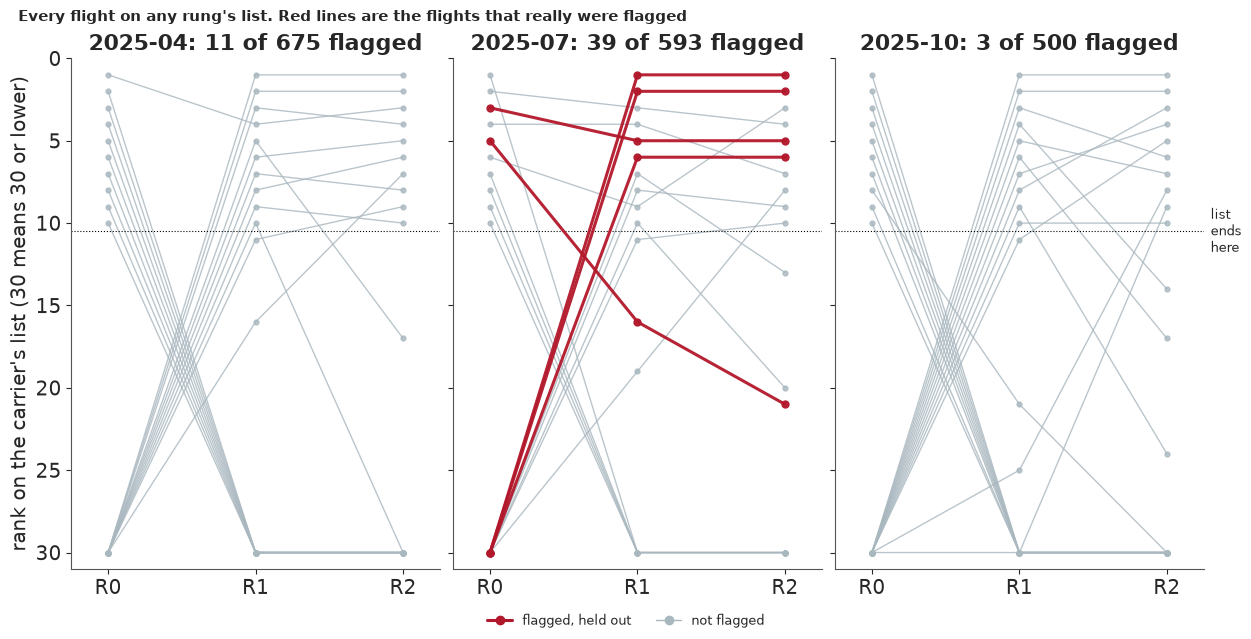

In [12]:
def decide(list_size=LIST_SIZE, needed=NEEDED, resamples=2000):
    """The rung rule, written down before any score was read, applied to each origin in turn."""
    rows, picks = [], {}
    for t, f in forecasts.items():
        part = f["table"]
        flagged = part["flagged"].to_numpy()
        airports = flight_origin[part["flight"].to_numpy()]
        codes, inverse = np.unique(airports, return_inverse=True)
        scores = {r: log_score(f[r], flagged) for r in ("R0", "R1", "R2")}
        means = {r: s.mean() for r, s in scores.items()}
        best = max(means, key=means.get)
        count = np.bincount(inverse)
        boot = np.random.default_rng([RANDOM_SEED, t]).integers(codes.size, size=(resamples, codes.size))
        se = {}
        for r, s in scores.items():
            gap = np.bincount(inverse, s - scores[best])
            se[r] = (gap[boot].sum(1) / count[boot].sum(1)).std()
        lists = {"R0": top(f["R0"], list_size, f["tie"]), "R1": top(f["R1"], list_size), "R2": top(f["R2"], list_size)}
        shared = {"R0": len(set(lists["R0"]) & set(lists["R1"])), "R1": len(set(lists["R1"]) & set(lists["R2"])), "R2": list_size}
        passes = {r: (means[best] - means[r] <= se[r]) and shared[r] >= needed for r in ("R0", "R1", "R2")}
        pick = next((r for r in ("R0", "R1", "R2") if passes[r]), None)
        picks[t] = pick or best
        for r in ("R0", "R1", "R2"):
            rows.append({"target": TARGET_NAMES[t], "rung": r, "log score": means[r], "gap to best": means[best] - means[r], "one SE": se[r],
                         f"hits in top {list_size}": int(flagged[lists[r]].sum()), "shared with next rung": shared[r], "passes": passes[r]})
        rows[-1]["picked"] = picks[t] if pick else f"{best} (none passed)"
    return pd.DataFrame(rows).set_index(["target", "rung"]), picks


with stage("scores"):
    verdict, picks = decide()
print(verdict.round(4).to_string())
print("Picks by origin:", {TARGET_NAMES[t]: r for t, r in picks.items()})
print("With a list of 50, which decides nothing:")
print(decide(list_size=50, needed=40)[0][["hits in top 50", "shared with next rung"]].unstack("rung").to_string())


def hit_gap(t, k=50, resamples=2000):
    """R2's extra hits over R1 in a list of k, with a 5-95% range from resampling origin airports."""
    f = forecasts[t]
    part, flagged = f["table"], f["table"]["flagged"].to_numpy(float)
    gain = np.zeros(flagged.size)
    gain[top(f["R2"], k)] += flagged[top(f["R2"], k)]
    gain[top(f["R1"], k)] -= flagged[top(f["R1"], k)]
    codes, inverse = np.unique(flight_origin[part["flight"].to_numpy()], return_inverse=True)
    boot = np.random.default_rng([RANDOM_SEED, t, 2]).integers(codes.size, size=(resamples, codes.size))
    low, high = np.quantile(np.bincount(inverse, gain)[boot].sum(1), [0.05, 0.95])
    return {"R2 less R1 hits": int(gain.sum()), "5%": low, "95%": high}


print("Top 50, airports resampled:", {TARGET_NAMES[t]: hit_gap(t) for t in TARGETS})
overlaps = {TARGET_NAMES[t]: [len(set(top(forecasts[t]["R1"], LIST_SIZE)) & set(top(p, LIST_SIZE))) for p in other_seeds[t]] for t in TARGETS}
print("R1 and R2 lists of 10 shared, on 12 other forecast seeds:", overlaps)
print("R2 hits in the top 50 on those seeds:", {TARGET_NAMES[t]: sorted({int(forecasts[t]["table"]["flagged"].to_numpy()[top(p, 50)].sum()) for p in other_seeds[t]})
                                                for t in TARGETS})
history = pd.DataFrame([{"target": TARGET_NAMES[t], "R1 12 months, all carriers": national_table.loc[TARGET_NAMES[t], "R1 score"],
                         "R1 3 months, all carriers": log_score(r1_forecast(t, months=3), national[t]["table"]["flagged"].to_numpy()).mean(),
                         "R1 12 months, this carrier": log_score(forecasts[t]["R1"], forecasts[t]["table"]["flagged"].to_numpy()).mean(),
                         "R1 3 months, this carrier": log_score(r1_forecast(t, CARRIER, months=3), forecasts[t]["table"]["flagged"].to_numpy()).mean(),
                         "R2, this carrier": log_score(forecasts[t]["R2"], forecasts[t]["table"]["flagged"].to_numpy()).mean()} for t in TARGETS]).set_index("target")
print(history.T.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(12.4, 6.3), sharey=True, layout="constrained")
LIMIT_RANK = 30
for ax, (t, f) in zip(axes, forecasts.items()):
    flagged = f["table"]["flagged"].to_numpy()
    ranks = {r: np.argsort(np.lexsort((-f["tie"] if r == "R0" else np.zeros(flagged.size), -f[r]))) + 1 for r in ("R0", "R1", "R2")}
    chosen = sorted(set().union(*(np.flatnonzero(v <= LIST_SIZE) for v in ranks.values())), key=lambda i: flagged[i])
    for i in chosen:
        y = [min(ranks[r][i], LIMIT_RANK) for r in ("R0", "R1", "R2")]
        hit = flagged[i]
        ax.plot(range(3), y, "-o", ms=5 if hit else 3.5, lw=2.2 if hit else 1, color=ALARM if hit else "#a9b7bf", alpha=0.95 if hit else 0.8, zorder=3 if hit else 2)
    ax.axhline(LIST_SIZE + 0.5, color="k", lw=0.8, ls=":")
    ax.set(xticks=range(3), xticklabels=["R0", "R1", "R2"], title=f"{TARGET_NAMES[t]}: {int(flagged.sum())} of {flagged.size} flagged", xlim=(-0.25, 2.25))
axes[0].set(ylim=(LIMIT_RANK + 1, 0), ylabel=f"rank on the carrier's list ({LIMIT_RANK} means {LIMIT_RANK} or lower)")
axes[-1].annotate("list\nends\nhere", (1, LIST_SIZE + 0.5), xycoords=("axes fraction", "data"), xytext=(5, 0),
                  textcoords="offset points", va="center", fontsize=9, annotation_clip=False)
fig.legend(handles=[Line2D([], [], color=ALARM, lw=2.2, marker="o", label="flagged, held out"),
                    Line2D([], [], color="#a9b7bf", lw=1, marker="o", label="not flagged")], loc="outside lower center", ncols=2, fontsize=9)
fig.suptitle("Every flight on any rung's list. Red lines are the flights that really were flagged", x=0.01, ha="left", fontsize=11);

**The rule picks R1 for April, and R2 for July and October, so R2 for this carrier. Read that
with the margins.** Only in July is R2's gain larger than its noise: a gap of 0.031 against an SE
of 0.009. In April and October R1 is within one SE, and in October it fails by one flight of
overlap, 7 shared where 8 are needed. If a single flight moved in October, the answer on this
carrier would be R1.

**April's pick is not firm either.** Twelve other forecast seeds on these same draws keep July at
8 and October at 7, and April at 8 in 11 of them and 7 in one. Two refits of April with other
sampler seeds, run outside this notebook (`fit_r2(TARGETS[0], seed=1)`, about 4 minutes each),
moved its overlap between 7 and 8 from one forecast seed to the next, 7 in 5 of 18. At 7 April
goes to R2. Integrating the month and the overdispersion exactly gave 8 on these draws and 7 on
both refits, while a refit of October stayed at 7. So R1 sits on the bar in April, and the picks
are best read as R2 at two months, possibly three. R2 on this carrier holds either way.

**The rule leans towards the dearer rung.** Its overlap test measures difference, not benefit: a
rung fails when the next rung's list differs, even if that list is no better. In October R2 is
bought with a gap inside one SE and 0 hits against 0. We keep the result, because the rule was
fixed in advance, but only July gives evidence that R2 is better.

**July's win may be partly a slow R1.** The 12-month window was fixed, never tested. Printed
above, an R1 on 3 months reacts faster: in July it scores -0.240 against -0.270 nationally, and
-0.239 against -0.248 on this carrier, where R2 still leads at -0.217. A short window is no free
gain, since it is worse in the calm months: -0.055 against -0.048 nationally in October. So part
of R2's July margin may be speed and not structure, and only a test of windows on all carriers
could tell.

**Yes, the list changes:** R1 and R2 share 7-8 of 10 and 20-28 of 50. **Whether that helps
depends on the length.** In a list of 10 they catch the same 0, 4 and 0 flagged flights, while
the 3 flags of October and 11 of April fall outside every list of 10. In a list of 50 R2 catches
3, 17 and 2 against R1's 0, 10 and 0. July's gain of 7 is noisy: its 5-95% range from resampling
airports runs from about 0 to 14. On this carrier 50 is about a tenth of all flights, far less
selective than a national 50, so this does not scale.

R0 barely overlaps anything, because it lists last month's flags. About half of the lines on the
chart run from R0's floor up to R1, and that move, from one month to twelve, is the largest
change in rank on the page, for a tenth of a second. It is not the largest change in what the
list catches: R1 to R2 adds more top-50 hits in all three months, and more score in April and
July.

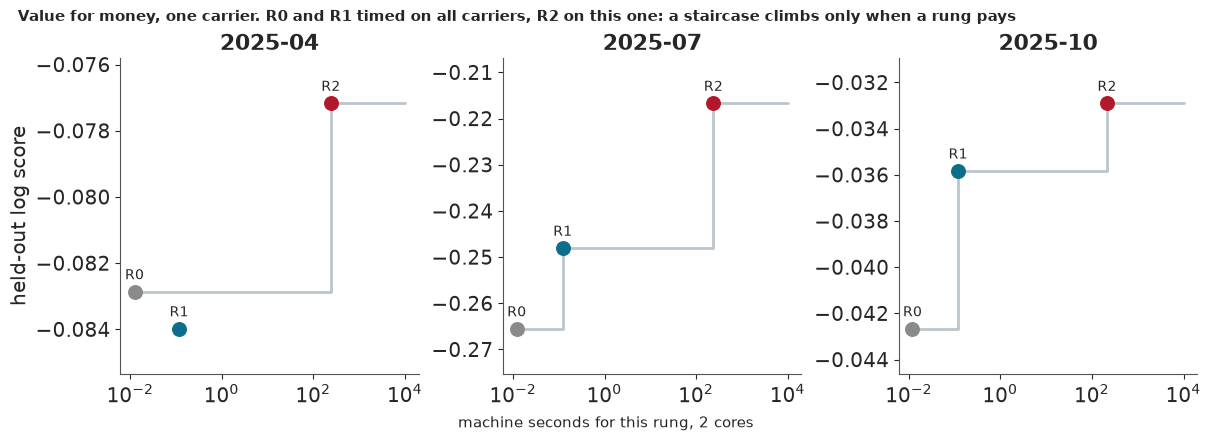

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), sharex=True, layout="constrained")
fit_seconds = {t: diagnostics[TARGET_NAMES[t]]["seconds"] for t in TARGETS}
for ax, (t, f) in zip(axes, forecasts.items()):
    seconds = [national[t]["seconds"]["R0"], national[t]["seconds"]["R1"], fit_seconds[t]]
    means = verdict.loc[TARGET_NAMES[t], "log score"].to_numpy()
    ax.step(seconds + [1e4], np.r_[np.maximum.accumulate(means), np.maximum.accumulate(means)[-1]], where="post", color="#b9c6cd", lw=2, zorder=1)
    for x, y, r in zip(seconds, means, ("R0", "R1", "R2")):
        ax.scatter([x], [y], s=95, color=RUNG_COLOUR[r], zorder=3)
        ax.annotate(r, (x, y), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=10)
    ax.set(xscale="log", title=TARGET_NAMES[t])
    ax.margins(y=0.2)
axes[0].set_ylabel("held-out log score")
fig.supxlabel("machine seconds for this rung, 2 cores", fontsize=11)
fig.suptitle("Value for money, one carrier. R0 and R1 timed on all carriers, R2 on this one: a staircase climbs only when a rung pays", x=0.01, ha="left", fontsize=11);

Each step up the staircase is a purchase, and a higher score is better. R1 costs about a tenth of
a second on every carrier, and R2 about 4 minutes on this one. Each panel has its own vertical
scale, because the months cannot be compared. In April R1 sits below R0 and pays nothing on
score. Note the axis: R0 and R1 are timed on all carriers and R2 on one carrier, which flatters
R2 by about 26x. Its national price is below.

## 8. What this run cost, and what to tell the charity

In [14]:
price = pd.Series(PRICE, name="seconds").round(0).astype(int)
print(price.to_string())
print(f"Total in stages: {price.sum() / 60:.1f} min on {CORES} cores")
assert {d.platform for d in jax.devices()} == {"cpu"}, "a reader's run must not start a GPU"
print("JAX saw CPU devices only, so this run used no GPU.")

r2_mean_s = np.mean([d["seconds"] for d in diagnostics.values()])
r2_cells_share = sizes.sum() / sizes[CARRIER]
gpu_three = f"{hours(r2_gpu_ms, 60_000, 3) * 60:.0f}-{hours(r2_gpu_ms, 160_000, 3) * 60:.0f} min"
window_three = [sum(hours(ms_14m * r / ROWS, g) for r in fit_rows["12-month window"]) for g in GRADIENTS]
ladder_of_prices = pd.DataFrame(
    [("R0, all carriers", f"{np.mean([f['seconds']['R0'] for f in national.values()]):.2f} s",
      f"{np.mean([f['seconds']['R0'] for f in national.values()]) * 3:.2f} s", "measured", "CPU, 2 cores"),
     ("R1, all carriers", f"{np.mean([f['seconds']['R1'] for f in national.values()]):.2f} s",
      f"{np.mean([f['seconds']['R1'] for f in national.values()]) * 3:.2f} s", "measured", "CPU, 2 cores"),
     ("R2, one carrier, nutpie", f"{r2_mean_s / 60:.1f} min", f"{r2_mean_s * 3 / 60:.0f} min", "measured", "CPU, 2 cores"),
     ("R2, all carriers, nutpie, every flight", f"{r2_mean_s * r2_cells_share / 3600:.1f} h or more", f"{r2_mean_s * r2_cells_share * 3 / 3600:.1f} h or more",
      "extrapolated", f"{r2_cells_share:.0f}x the cells, same gradient count; d about 14x larger"),
     ("R2, all carriers, 3-cell cut, ChEES", f"{hours(r2_gpu_ms, 60_000) * 60:.0f}-{hours(r2_gpu_ms, 160_000) * 60:.0f} min, plus extra restarts",
      f"{gpu_three}, plus extra restarts", "extrapolated", "measured gradient x assumed count; ChEES never run on R2"),
     ("R3, all rows, ChEES", f"{hours(ms_14m, 60_000):.1f}-{hours(ms_14m, 160_000):.1f} h, plus extra restarts",
      f"{window_three[0]:.1f}-{window_three[1]:.1f} h on the 12-month window", "extrapolated",
      "no float32 test, gradient count unmeasured, E86's recipe needs a 2,080 GiB table")],
    columns=["rung", "one forecast", "three test months", "label", "basis"]).set_index("rung")
print(ladder_of_prices.to_string())
print(f"One more tree doubling would make nutpie's three months about {r2_mean_s * r2_cells_share * 6 / 3600:.0f} h.")
timing_free = {k: {name: value for name, value in v.items() if name != "seconds"} for k, v in diagnostics.items()}
store.save_json("decide", {"verdict": verdict.reset_index().to_dict("list"), "picks": {TARGET_NAMES[t]: r for t, r in picks.items()},
                           "diagnostics": timing_free, "national": national_table.reset_index().to_dict("list")});

timing rows 1-5              9
row 5 ladder                 9
R0 and R1, all carriers      1
R2, one carrier, 3 fits    725
scores                       0
Total in stages: 12.4 min on 2 cores
JAX saw CPU devices only, so this run used no GPU.
                                                          one forecast                  three test months         label                                                                             basis
rung                                                                                                                                                                                                     
R0, all carriers                                                0.01 s                             0.04 s      measured                                                                      CPU, 2 cores
R1, all carriers                                                0.12 s                             0.36 s      measured                                

The table prices one forecast and the three test months. R3's one forecast uses all 24 months,
and its three test months use the 12-month window. Measured peak memory and wall time are in the
banner, and each extrapolated line says what it rests on.

### How to write a price someone can check

A quote is a sentence with five parts: what is bought, on what hardware, measured from what, the
range, and what would make it wrong. Compare

> "Two hours on one GPU."

with

> "One fit of the row-level model for one forecast month costs 2.6-7.0 hours on an RTX 3090 Ti at
> 32 chains, scaled 1.41x from a measured 10-million-row gradient of 112 ms, for 60,000-160,000
> gradients. It takes longer if warmup must restart more than E86's did, if R3 needs more
> gradients than E86, or if float32 fails at 14 million rows. It needs a sampler that fits in
> memory at 747,000 parameters, which E86's recipe does not. Nobody has shown what it does to the
> list."

The second can be checked, argued with and refused. The series rule starts here: every large
notebook opens with its price table and the smallest model that could answer the question, and
says whether the big model changed the decision.

### What to tell the charity

1. **Do not approve the quote as written.** Ask the contractor to restate it with a measured
   gradient count, warmup included, a float32 test at 14 million rows, a sampler that fits in
   memory at this size, and three test months, not one.
2. **Start the list now with a counting rule: rank by R0 and print R1's chance beside each
   flight.** Both take under a second. Built from last month's file, as a real list must be, R0's
   top 50 held 4, 35 and 15 flagged flights in the three months and R1's 6, 31 and 6. Over 12
   months R0 held 130 against 103, and R1 had the better log score in 11. Say "likely to be
   flagged", and say it is an estimate.
3. **Buy one test next: R2 on all carriers, on the same three months.** Two versions price, and
   neither has run. ChEES on the 3-cell cut, where 24% of cells lose their flight's own effect,
   is about 16-43 minutes on the GPU plus any further warmup restarts. nutpie with every flight
   is about 4.8-5.1 hours or more on 2 cores. Either fits one night at those figures, and the
   CPU version has little room: one more tree doubling is about 10 hours. If its national list adds nothing to R1's, the row-level
   question goes away. On one carrier the evidence for R2 is real and thin.
4. **Expect months, not flights, to decide how good a list looks.** Flags ran from 25 to 1,686 a
   month. No model here saw July coming, and a hit rate from one month should not be quoted
   alone.

### What this notebook cannot claim

- **That R3 changes a list, or does not.** R3 was never fitted, at any size, on any carrier.
- **That R2 is worth buying nationally.** It was fitted on one carrier, 3.9% of the cells, and
  three months, and neither national version has run.
- **That April's pick is firm, or that 12 months is the right window.** One flight decides it,
  and the window was never tested.
- **That 2.6-7.0 hours is what R3 would take.** The rate is measured to 10M rows. The gradient
  counts are assumptions, and further warmup restarts, float32 and R3's geometry are not priced.
- **That E86's recipe can run R3.** Its d x d table would need about 2,080 GiB, and the way
  around it is untested.
- **That float32 fails at 14M rows, or passes.** The spacing is arithmetic and the check was not
  run.
- **That the GPU beats a well-run CPU.** CPU figures are on 2 threads. The wider CPU test was not
  allowed on this machine.
- **That sorting never helps a GPU.** One scatter on one card, at 8 chains. The plan's bucket
  variant, a hand-written reverse pass over rows grouped in power-of-2 buckets, was not run.
- **A speed for your laptop.** Every CPU time here is from one Ryzen 5950X on 2 cores, 8 cores
  were not timed, and every GPU time is from one RTX 3090 Ti.
- **That a flagged flight is a violation, or a verdict on a carrier.** This is our coding of the
  rule, and only an estimate.
- **That the linking is right.** Flights are clusters linked across months by our own rule, and
  some real flights are split: 28% of new eligible flights had the same number in the same market
  the month before.

**The bigger lesson is the plain order of work.** Price before you buy, measure before you claim,
and let the smallest model that answers the question go first. It may be the answer.

## Try it yourself

Each of these ran as printed after the finished notebook, on 2 cores. The first two take under a
second, and the third about 75 seconds.

1. **A cost law from less.** `predict_month(fit_days=(3, 7))` and `predict_month(fit_days=(7,
   14), chains=1)` fit the law above on other sizes. One sits across the step and overshoots the
   month several times over; the other sits above it and lands within about 10%. Which is which,
   and could you have known in advance?
2. **A longer list.** `decide(list_size=20, needed=16)[1]` reruns the rule with a list of 20 and
   the same 80% overlap, and it gives R2 at all three months. Print `decide(list_size=20,
   needed=16)[0]` to see what changed for April. Why would a rule be fixed before reading the
   scores, list length included?
3. **Another carrier.** Take the 10th of 15 with `other = int(np.argsort(-sizes)[9])`, fit it
   with fewer draws with `small_fit = fit_r2(TARGETS[1], carrier=other, tune=400, draws=300)`,
   then compare `log_score(r2_forecast(small_fit, other)["R2"], targets_of(TARGETS[1],
   other)["flagged"]).mean()` with `log_score(r1_forecast(TARGETS[1], other),
   targets_of(TARGETS[1], other)["flagged"]).mean()`. Read `small_fit["stats"]` first: at these
   short settings the hyperparameters' r_hat is about 1.06, which fails this notebook's own bar.
   One more carrier is one more story, not a national answer.